
# 🌾 PadiCek — Deteksi Penyakit Daun Padi dengan CNN

| Langkah | Isi |
|---|---|
| 1 | Menyiapkan file pendukung (`info_penyakit.py`, `fitur_unik.py`, `app.py`) |
| 2 | Konfigurasi |
| 3 | Mengambil dataset langsung dari Kaggle |
| 4 | **Preprocessing a** — pembersihan data (duplikat, data rusak, label salah) |
| 5 | Exploratory Data Analysis (EDA) |
| 6 | **Preprocessing b** — resize, rescale piksel, fokus daun |
| 7 | **Preprocessing c** — augmentasi data (jenis & parameter) |
| 8 | **Preprocessing d** — missing value, outlier, ketidakseimbangan kelas |
| 9 | **Preprocessing e** — pembagian data & pencegahan kebocoran |
| 10 | Arsitektur CNN |
| 11 | Training 3 skenario & pemilihan model final |
| 12 | **Hasil evaluasi a** — metrik dan alasannya |
| 13 | **Hasil evaluasi b** — nilai metrik pada data testing |
| 14 | **Hasil evaluasi c** — grafik loss & akurasi |
| 15 | Fitur unik 1: Grad-CAM (+ cek fokus pada daun) |
| 16 | Fitur unik 2: ambang keyakinan & deteksi input di luar domain |
| 17 | **Hasil evaluasi d** — perbandingan antarskenario & dengan/tanpa fitur unik |
| 18 | **Hasil evaluasi e** — analisis kesalahan & over/underfitting |
| 19 | Simpan model & hasil |
| 20 | Unduh `padicek_lengkap.zip` |
| 21 | Menyalakan website dengan link publik |

> Jika Colab terputus di tengah jalan, cukup **Runtime → Run all** lagi: model yang sudah selesai dilatih
> dimuat dari `model/skenario/` sehingga tidak perlu training ulang.

### Cara pakai
1. Menu **Runtime → Change runtime type → T4 GPU → Save**.
2. Menu **Runtime → Run all**. Total ±40–60 menit (tiga skenario, maksimum 50 epoch dengan EarlyStopping).
3. Di akhir: `padicek_lengkap.zip` terunduh dan link website muncul di sel paling bawah.


## Langkah 1. Menyiapkan file pendukung
Sel-sel berikut menulis file yang dipakai training dan website: data penyakit (`info_penyakit.py`), dua fitur unik (`fitur_unik.py`), dan website (`app.py`). Cukup dijalankan, tidak perlu diubah.

In [ ]:
import os, sys
BASE = "/content" if os.path.isdir("/content") else os.getcwd()
if os.path.basename(BASE) == "padicek":
    BASE = os.path.dirname(BASE)
os.makedirs(f"{BASE}/padicek/.streamlit", exist_ok=True)
os.chdir(f"{BASE}/padicek")
sys.path.insert(0, os.getcwd())
print("Folder kerja:", os.getcwd())

Folder kerja: /content/padicek


In [ ]:
%%writefile info_penyakit.py
import re

INFO = {
    "bacterial_leaf_blight": {
        "nama": "Hawar Daun Bakteri (Kresek)",
        "nama_latin": "Bacterial Leaf Blight",
        "penyebab": "Bakteri Xanthomonas oryzae pv. oryzae",
        "gejala": (
            "Bercak kebasahan berwarna hijau keabu-abuan dimulai dari ujung atau tepi daun, "
            "kemudian meluas menjadi garis kuning hingga putih keabu-abuan dengan tepi bergelombang. "
            "Pada serangan berat daun mengering seperti terbakar."
        ),
        "penanganan": [
            "Gunakan varietas tahan dan benih sehat bersertifikat.",
            "Hindari pemupukan nitrogen (urea) berlebihan; seimbangkan dengan kalium.",
            "Atur pengairan berselang (intermittent) dan jaga sanitasi pematang.",
            "Konsultasikan pengendalian kimia dengan penyuluh pertanian setempat bila serangan meluas.",
        ],
        "sehat": False,
    },
    "brown_spot": {
        "nama": "Bercak Coklat",
        "nama_latin": "Brown Spot",
        "penyebab": "Jamur Bipolaris oryzae (Cochliobolus miyabeanus)",
        "gejala": (
            "Bercak oval berwarna coklat dengan bagian tengah keabu-abuan dan tepi coklat kemerahan, "
            "tersebar merata di permukaan daun. Sering muncul pada tanah yang miskin hara."
        ),
        "penanganan": [
            "Perbaiki kesuburan tanah dengan pemupukan berimbang (terutama kalium dan silika).",
            "Gunakan benih sehat dan lakukan perlakuan benih sebelum tanam.",
            "Bersihkan sisa tanaman terinfeksi setelah panen.",
            "Gunakan fungisida sesuai anjuran penyuluh bila serangan berat.",
        ],
        "sehat": False,
    },
    "healthy_rice_leaf": {
        "nama": "Daun Sehat",
        "nama_latin": "Healthy Rice Leaf",
        "penyebab": "-",
        "gejala": "Daun berwarna hijau merata tanpa bercak, garis, atau bagian yang mengering.",
        "penanganan": [
            "Pertahankan pemupukan berimbang dan pengairan yang baik.",
            "Lakukan pemantauan rutin minimal sekali seminggu untuk deteksi dini.",
        ],
        "sehat": True,
    },
    "leaf_blast": {
        "nama": "Blas Daun",
        "nama_latin": "Leaf Blast",
        "penyebab": "Jamur Pyricularia oryzae (Magnaporthe oryzae)",
        "gejala": (
            "Bercak berbentuk belah ketupat (seperti mata) dengan bagian tengah putih keabu-abuan "
            "dan tepi coklat. Bercak dapat menyatu sehingga daun mengering."
        ),
        "penanganan": [
            "Tanam varietas tahan blas dan lakukan pergiliran varietas.",
            "Hindari pupuk nitrogen berlebihan dan jarak tanam terlalu rapat.",
            "Musnahkan jerami dan sisa tanaman yang terinfeksi.",
            "Aplikasikan fungisida sesuai anjuran penyuluh pada awal gejala.",
        ],
        "sehat": False,
    },
    "leaf_scald": {
        "nama": "Hangus Daun (Leaf Scald)",
        "nama_latin": "Leaf Scald",
        "penyebab": "Jamur Microdochium oryzae (Monographella albescens)",
        "gejala": (
            "Bercak memanjang mulai dari ujung atau tepi daun dengan pola pita bergelombang "
            "berwarna coklat muda hingga coklat kemerahan, sehingga ujung daun tampak hangus."
        ),
        "penanganan": [
            "Gunakan benih sehat dan varietas yang lebih tahan.",
            "Kurangi pemupukan nitrogen berlebihan.",
            "Jaga jarak tanam agar sirkulasi udara baik dan kelembapan tidak terlalu tinggi.",
            "Konsultasikan penggunaan fungisida dengan penyuluh pertanian.",
        ],
        "sehat": False,
    },
    "sheath_blight": {
        "nama": "Hawar Pelepah",
        "nama_latin": "Sheath Blight",
        "penyebab": "Jamur Rhizoctonia solani",
        "gejala": (
            "Bercak oval kehijauan hingga abu-abu dengan tepi coklat pada pelepah dan daun, "
            "biasanya dimulai dekat permukaan air lalu menjalar ke atas."
        ),
        "penanganan": [
            "Atur jarak tanam tidak terlalu rapat (misalnya sistem jajar legowo).",
            "Hindari pemupukan nitrogen berlebihan.",
            "Keringkan petak sawah secara berkala untuk menurunkan kelembapan.",
            "Gunakan fungisida atau agens hayati (misalnya Trichoderma) sesuai anjuran penyuluh.",
        ],
        "sehat": False,
    },
}

_KATA_KUNCI = {
    "bacterial_leaf_blight": ["bacterial", "blight_bact", "bacterialleafblight", "blb"],
    "brown_spot": ["brown"],
    "healthy_rice_leaf": ["healthy", "sehat", "normal"],
    "leaf_blast": ["blast"],
    "leaf_scald": ["scald"],
    "sheath_blight": ["sheath"],
}


def _normal(teks: str) -> str:
    return re.sub(r"[^a-z0-9]", "", teks.lower())


def cari_info(nama_kelas: str) -> dict:
    """Mengembalikan info penyakit untuk nama folder kelas apa pun dari dataset."""
    n = _normal(nama_kelas)
    for kunci, daftar in _KATA_KUNCI.items():
        if any(_normal(k) in n for k in daftar):
            return INFO[kunci]

    return {
        "nama": nama_kelas.replace("_", " ").title(),
        "nama_latin": nama_kelas,
        "penyebab": "-",
        "gejala": "-",
        "penanganan": ["Konsultasikan dengan penyuluh pertanian setempat."],
        "sehat": False,
    }


def nama_indonesia(nama_kelas: str) -> str:
    return cari_info(nama_kelas)["nama"]

Writing info_penyakit.py


In [ ]:
%%writefile fitur_unik.py

import numpy as np
import tensorflow as tf
import keras

LAPISAN_KONV_TERAKHIR = "blok4_relu"
AMBANG_DEFAULT = 0.60
AMBANG_MINIMUM = 0.50
FORMAT_GAMBAR = ["jpg", "jpeg", "jfif", "png", "webp", "bmp", "gif", "tif", "tiff"]


def buka_gambar(sumber):
    """Membuka gambar dari file/upload dengan aman untuk berbagai format dari internet/HP:
    rotasi EXIF, PNG/WEBP transparan (ditempel di atas latar putih), PNG 16-bit, CMYK,
    palet warna, dan GIF animasi (diambil frame pertama). Hasil: PIL Image RGB 8-bit."""
    from PIL import Image, ImageOps

    img = Image.open(sumber)
    if getattr(img, "is_animated", False):
        img.seek(0)
    img = ImageOps.exif_transpose(img)
    if img.mode in ("I;16", "I;16B", "I;16L", "I"):              # 16/32-bit -> skala ke 0-255
        arr = np.asarray(img, dtype=np.float64)
        maks = arr.max() if arr.max() > 0 else 1.0
        img = Image.fromarray(np.uint8(arr / maks * 255)).convert("L")
    if img.mode == "P":
        img = img.convert("RGBA" if "transparency" in img.info else "RGB")
    if img.mode in ("RGBA", "LA"):
        latar = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(latar, img.convert("RGBA"))
    return img.convert("RGB")

def peta_daun(x, ukuran_peta=112):
    """Peta area daun bergejala (0-1) dari batch gambar x (B, H, W, 3) bernilai 0-255.
    1) Warna gejala (kuning, jingga, coklat, kemerahan) dicari di ruang warna HSV.
    2) Opening (erosi lalu dilasi 3x3) membuang bintik kecil/noise.
    3) Dilasi 9x9 menyatukan bercak-bercak menjadi satu area daun.
    4) Konvolusi rata-rata 7x7 menghaluskan tepi peta.
    Erosi = -maxpool(-x) dan dilasi = maxpool(x): operasi morfologi dalam bentuk konvolusi."""
    x = tf.convert_to_tensor(x, tf.float32)
    tinggi, lebar = tf.shape(x)[1], tf.shape(x)[2]
    kecil = tf.clip_by_value(tf.image.resize(x, (ukuran_peta, ukuran_peta)) / 255.0, 0.0, 1.0)
    hsv = tf.image.rgb_to_hsv(kecil)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    gejala = ((h < 50 / 360) | (h > 340 / 360)) & (s > 0.22) & (v > 0.20)
    m = tf.cast(gejala, tf.float32)[..., None]
    m = -tf.nn.max_pool2d(-m, 3, 1, "SAME")          # erosi
    m = tf.nn.max_pool2d(m, 3, 1, "SAME")            # dilasi (opening selesai)
    m = tf.nn.max_pool2d(m, 13, 1, "SAME")           # dilasi besar: satukan bercak jadi area daun
    m = tf.nn.avg_pool2d(m, 7, 1, "SAME")            # haluskan tepi
    return tf.image.resize(m, (tinggi, lebar))


@keras.saving.register_keras_serializable(package="PadiCek")
class FokusDaun(keras.layers.Layer):
    """Lapisan preprocessing di awal model: area daun bergejala tetap tajam, latar belakang dikaburkan.
    Jika area gejala < min_cakupan (misalnya daun sehat), gambar dibiarkan utuh."""

    def __init__(self, min_cakupan=0.02, **kwargs):
        super().__init__(**kwargs)
        self.min_cakupan = min_cakupan

    def call(self, x):
        m = peta_daun(x)
        cakupan = tf.reduce_mean(tf.cast(m > 0.5, tf.float32), axis=[1, 2, 3], keepdims=True)
        m = tf.where(cakupan >= self.min_cakupan, m, tf.ones_like(m))
        kabur = tf.nn.avg_pool2d(tf.nn.avg_pool2d(x, 11, 1, "SAME"), 11, 1, "SAME")
        return m * x + (1.0 - m) * kabur

    def get_config(self):
        return {**super().get_config(), "min_cakupan": self.min_cakupan}


def terapkan_fokus(gambar, min_cakupan=0.02):
    """Versi numpy untuk tampilan: (hasil fokus daun, peta daun 0-1, cakupan)."""
    g = np.asarray(gambar, dtype=np.float32)[None]
    m = peta_daun(g)[0, ..., 0].numpy()
    hasil = FokusDaun(min_cakupan)(tf.constant(g))[0].numpy()
    return hasil, m, float((m > 0.5).mean())


def fokus_gradcam_pada_daun(model_gradcam, gambar_list, min_cakupan=0.02):
    """Mengukur bug 'Grad-CAM menyorot latar': porsi energi Grad-CAM yang jatuh di area daun bergejala
    dibanding luas area tersebut. Rasio > 1 berarti model lebih memperhatikan daun daripada latar."""
    from PIL import Image
    energi, luas = [], []
    for g in gambar_list:
        g = np.asarray(g, dtype=np.float32)
        m = peta_daun(g[None])[0, ..., 0].numpy() > 0.5
        if m.mean() < min_cakupan:
            continue
        cam, _ = gradcam(model_gradcam, g)
        cam = np.asarray(Image.fromarray(np.float32(cam)).resize(g.shape[1::-1], Image.BILINEAR))
        energi.append(float((cam * m).sum() / (cam.sum() + 1e-8))); luas.append(float(m.mean()))
    if not energi:
        return {"n": 0, "energi_di_daun": 0.0, "luas_daun": 0.0, "rasio": 0.0, "porsi_gambar_fokus": 0.0}
    e, l = np.array(energi), np.array(luas)
    return {"n": int(len(e)), "energi_di_daun": float(e.mean()), "luas_daun": float(l.mean()),
            "rasio": float(e.mean() / (l.mean() + 1e-8)), "porsi_gambar_fokus": float((e > l).mean())}


def siapkan_gambar(gambar, ukuran):
    """Resize PERSIS seperti pipeline training (tf.image.resize bilinear), lalu kembalikan array
    float32 bernilai 0-255. Dipakai website, Grad-CAM, dan uji luar domain agar tidak ada
    perbedaan preprocessing antara training dan pemakaian (train-serving skew)."""
    import tensorflow as tf

    arr = np.asarray(gambar.convert("RGB") if hasattr(gambar, "convert") else gambar, dtype=np.float32)
    return tf.image.resize(arr, (ukuran, ukuran)).numpy()


def buat_model_gradcam(model):
    """Model bantu: input gambar -> (feature map konvolusi terakhir, probabilitas kelas)."""
    import tensorflow as tf

    return tf.keras.Model(model.inputs,
                          [model.get_layer(LAPISAN_KONV_TERAKHIR).output, model.output])


def gradcam(model_gradcam, gambar, kelas=None):
    """Menghitung heatmap Grad-CAM (Selvaraju dkk., 2017).

    gambar : array (H, W, 3) bernilai 0-255 (tanpa normalisasi, rescaling ada di dalam model)
    kelas  : indeks kelas yang dijelaskan; None = kelas dengan probabilitas tertinggi
    return : (heatmap ukuran feature map bernilai 0-1, vektor probabilitas)
    """
    import tensorflow as tf

    x = tf.convert_to_tensor(np.asarray(gambar, dtype=np.float32)[None, ...])
    with tf.GradientTape() as tape:
        fitur, prob = model_gradcam(x, training=False)
        if kelas is None:
            kelas = int(tf.argmax(prob[0]))
        skor = prob[:, kelas]
    grad = tape.gradient(skor, fitur)                    # d skor / d feature map
    bobot = tf.reduce_mean(grad, axis=(1, 2))            # rata-rata gradien per filter
    cam = tf.nn.relu(tf.reduce_sum(fitur * bobot[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), prob[0].numpy()

def tempel_heatmap(gambar, cam, alpha=0.45):
    """Menimpa heatmap (colormap 'jet') di atas gambar asli. Mengembalikan array uint8."""
    from matplotlib import colormaps
    from PIL import Image

    gambar = np.clip(np.asarray(gambar), 0, 255).astype(np.uint8)
    h, w = gambar.shape[:2]
    cam_besar = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize((w, h), Image.BILINEAR)) / 255.0
    warna = colormaps["jet"](cam_besar)[..., :3] * 255
    return np.uint8(gambar * (1 - alpha) + warna * alpha)

def status_prediksi(prob, ambang=AMBANG_DEFAULT, minimum=AMBANG_MINIMUM):
    """Fitur 2: tiga tingkat keyakinan.
    - 'yakin'           : keyakinan >= ambang (dipilih dari data validasi) -> hasil ditampilkan penuh
    - 'perlu dicek'     : minimum <= keyakinan < ambang -> dugaan tetap ditampilkan + peringatan
    - 'tidak dikenali'  : keyakinan < minimum (kelas teratas tidak lebih besar dari gabungan kelas lain)
                          -> kemungkinan bukan daun padi / foto kurang jelas, pengguna diminta foto ulang"""
    keyakinan = float(np.max(prob))
    if keyakinan >= ambang:
        return "yakin", keyakinan
    return ("perlu dicek" if keyakinan >= min(minimum, ambang) else "tidak dikenali"), keyakinan


def pilih_ambang(prob_val, y_val, kandidat=None, target_akurasi=0.95):
    """Memilih ambang terkecil yang membuat akurasi prediksi yang diterima pada data VALIDASI
    mencapai target. Data uji tidak dipakai agar evaluasi tetap jujur."""
    kandidat = kandidat or [round(0.50 + 0.05 * i, 2) for i in range(10)]   # 0,50 ... 0,95
    keyakinan = prob_val.max(axis=1)
    benar = prob_val.argmax(axis=1) == y_val
    for t in kandidat:
        diterima = keyakinan >= t
        if diterima.sum() > 0 and benar[diterima].mean() >= target_akurasi:
            return float(t)
    return float(kandidat[-1])


def tabel_ambang(prob, y, kandidat):
    """Cakupan (porsi prediksi yang diterima) dan akurasi prediksi yang diterima untuk tiap ambang."""
    keyakinan = prob.max(axis=1)
    benar = prob.argmax(axis=1) == y
    baris = []
    for t in kandidat:
        d = keyakinan >= t
        baris.append({"ambang": float(t), "cakupan": float(d.mean()),
                      "akurasi": float(benar[d].mean()) if d.sum() else 0.0, "n_diterima": int(d.sum())})
    return baris


def buat_input_luar_domain(contoh_gambar, ukuran, n_per_jenis=40, seed=42):
    """Membuat gambar uji 'di luar domain' untuk menguji fitur 2:
    - noise acak, - warna polos/gradien, - potongan daun yang diacak (warna mirip, struktur hilang)."""
    rng = np.random.default_rng(seed)
    hasil = {"Noise acak": [], "Warna polos & gradien": [], "Potongan citra diacak": []}
    for _ in range(n_per_jenis):
        hasil["Noise acak"].append(rng.integers(0, 256, (ukuran, ukuran, 3)).astype(np.float32))
        warna_a, warna_b = rng.integers(0, 256, 3), rng.integers(0, 256, 3)
        t = np.linspace(0, 1, ukuran)[None, :, None] if rng.random() < 0.5 else np.zeros((1, 1, 1))
        hasil["Warna polos & gradien"].append((warna_a * (1 - t) + warna_b * t + np.zeros((ukuran, ukuran, 3)))
                                              .astype(np.float32))
        g = np.asarray(contoh_gambar[rng.integers(len(contoh_gambar))], dtype=np.float32)
        k = ukuran // 8
        ubin = [g[i:i + k, j:j + k] for i in range(0, k * 8, k) for j in range(0, k * 8, k)]
        rng.shuffle(ubin)
        acak = np.zeros_like(g)
        for idx, u in enumerate(ubin):
            i, j = divmod(idx, 8)
            acak[i * k:(i + 1) * k, j * k:(j + 1) * k] = u
        hasil["Potongan citra diacak"].append(acak)
    return {k: np.stack(v) for k, v in hasil.items()}


def uji_penghapusan_gradcam(model_gradcam, model, gambar_list, porsi=0.2, seed=42):
    """Bukti dampak Grad-CAM (deletion test): menutup 20% area yang paling 'merah' menurut
    Grad-CAM lalu membandingkan penurunan keyakinan dengan menutup 20% area acak.
    Jika Grad-CAM benar menunjuk area penting, penurunannya harus lebih besar."""
    from PIL import Image

    rng = np.random.default_rng(seed)
    turun_cam, turun_acak = [], []
    for g in gambar_list:
        g = np.asarray(g, dtype=np.float32)
        cam, prob = gradcam(model_gradcam, g)
        kelas = int(prob.argmax())
        n = max(1, int(round(cam.size * porsi)))
        topk = np.zeros(cam.size, bool); topk[np.argsort(cam.ravel())[-n:]] = True
        acak = np.zeros(cam.size, bool); acak[rng.choice(cam.size, n, replace=False)] = True
        hasil = []
        for m in (topk, acak):
            topeng = np.asarray(Image.fromarray(np.uint8(m.reshape(cam.shape)) * 255)
                                .resize(g.shape[1::-1], Image.NEAREST)) > 0
            tertutup = g.copy(); tertutup[topeng] = 127.0
            hasil.append(float(model.predict(tertutup[None], verbose=0)[0][kelas]))
        turun_cam.append(prob[kelas] - hasil[0]); turun_acak.append(prob[kelas] - hasil[1])
    return {"n": len(gambar_list), "porsi_area": porsi,
            "penurunan_gradcam": float(np.mean(turun_cam)), "penurunan_acak": float(np.mean(turun_acak)),
            "persen_lebih_besar": float(np.mean(np.array(turun_cam) > np.array(turun_acak)))}

Writing fitur_unik.py


In [ ]:
%%writefile app.py

import json
import os

os.chdir(os.path.dirname(os.path.abspath(__file__)))

import numpy as np
import streamlit as st
from PIL import Image

import fitur_unik as fu
from info_penyakit import cari_info

MODEL_PATH = "model/padicek_model.keras"
LABEL_PATH = "model/labels.json"
METRICS_PATH = "hasil/metrics.json"

st.set_page_config(page_title="PadiCek – Deteksi Penyakit Daun Padi", page_icon="🌾", layout="centered")

st.markdown(
    """
    <style>
      .hasil-box {border-radius: 12px; padding: 1.1rem 1.3rem; margin: .6rem 0 1rem;}
      .hasil-sakit {background: #fdf1e6; border: 1px solid #e8b27a;}
      .hasil-sehat {background: #ebf6ec; border: 1px solid #8cc895;}
      .hasil-ragu {background: #f2f2f2; border: 1px dashed #9a9a9a;}
      .hasil-label {font-size: .85rem; color: #5b5b5b; margin: 0;}
      .hasil-nama {font-size: 1.6rem; font-weight: 700; margin: .1rem 0 .2rem; color: #1e1e1e;}
      .hasil-latin {font-style: italic; color: #5b5b5b; margin: 0;}
      @media (prefers-color-scheme: dark) {
        .hasil-sakit {background: #3a2a1a; border-color: #8a5a2b;}
        .hasil-sehat {background: #1c3320; border-color: #3f7a48;}
        .hasil-ragu {background: #2a2a2a; border-color: #777;}
        .hasil-nama {color: #f2f2f2;} .hasil-label, .hasil-latin {color: #c9c9c9;}
      }
    </style>
    """,
    unsafe_allow_html=True,
)


@st.cache_resource(show_spinner="Memuat model CNN...")
def muat_model():
    import tensorflow as tf

    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    with open(LABEL_PATH) as f:
        meta = json.load(f)
    return (model, fu.buat_model_gradcam(model), meta["class_names"], int(meta.get("img_size", 224)),
            float(meta.get("ambang_keyakinan", fu.AMBANG_DEFAULT)), float(meta.get("ambang_minimum", fu.AMBANG_MINIMUM)))


@st.cache_data
def muat_metrics():
    if os.path.exists(METRICS_PATH):
        with open(METRICS_PATH) as f:
            return json.load(f)
    return None


def siapkan(gambar: Image.Image, img_size: int, potong=(0, 0, 0, 0)):
    """potong = persen dipotong dari (kiri, atas, kanan, bawah) agar daun memenuhi bingkai.
    Mengembalikan (input model img_size x img_size, foto asli setelah dipotong untuk ditampilkan)."""
    w, h = gambar.size
    kiri, atas, kanan, bawah = potong
    kotak = (int(w * kiri / 100), int(h * atas / 100), int(w * (1 - kanan / 100)), int(h * (1 - bawah / 100)))
    if kotak[2] - kotak[0] > 8 and kotak[3] - kotak[1] > 8:
        gambar = gambar.crop(kotak)
    return fu.siapkan_gambar(gambar, img_size), gambar
st.title("🌾 PadiCek")
st.caption("Deteksi penyakit daun padi dari foto menggunakan Convolutional Neural Network (CNN)")

if not os.path.exists(MODEL_PATH):
    st.error(
        "File model belum ada. Jalankan training terlebih dahulu (jalankan_padicek.py / train.py / notebook), "
        "lalu pastikan folder `model/` dan `hasil/` berada di folder yang sama dengan app.py."
    )
    st.stop()

model, model_cam, CLASS_NAMES, IMG_SIZE, AMBANG, MINIMUM = muat_model()
metrics = muat_metrics()

tab_deteksi, tab_performa, tab_info, tab_tentang = st.tabs(
    ["🔍 Deteksi", "📊 Performa Model", "📚 Info Penyakit", "ℹ️ Tentang"]
)

with tab_deteksi:
    st.write("Unggah foto daun padi (dari HP, kamera, atau internet), atau ambil foto langsung dengan kamera. "
             "Hasil paling akurat jika **satu helai daun** yang sakit terlihat jelas dan memenuhi sebagian besar foto.")
    sumber = st.radio("Sumber foto", ["Unggah file", "Kamera"], horizontal=True, label_visibility="collapsed")
    berkas = (st.file_uploader("Pilih foto daun padi", type=fu.FORMAT_GAMBAR,
                               help="Format: " + ", ".join(f.upper() for f in fu.FORMAT_GAMBAR))
              if sumber == "Unggah file" else st.camera_input("Ambil foto daun padi"))

    if berkas is not None:
        try:
            gambar = fu.buka_gambar(berkas)
        except Exception:
            st.error("File tidak dapat dibaca sebagai gambar. Coba simpan ulang gambar sebagai JPG lalu unggah lagi.")
            st.stop()

        with st.expander("✂️ Potong foto agar daun memenuhi bingkai (opsional)"):
            st.caption("Foto dari internet sering memuat banyak latar (sawah, tanah, langit). Potong tepi foto "
                       "sampai daun yang sakit berada di tengah dan terlihat besar.")
            c1, c2 = st.columns(2)
            p_kiri = c1.slider("Potong kiri (%)", 0, 45, 0)
            p_kanan = c2.slider("Potong kanan (%)", 0, 45, 0)
            p_atas = c1.slider("Potong atas (%)", 0, 45, 0)
            p_bawah = c2.slider("Potong bawah (%)", 0, 45, 0)
        arr, foto = siapkan(gambar, IMG_SIZE, (p_kiri, p_atas, p_kanan, p_bawah))
        tampil = foto.copy()
        tampil.thumbnail((1600, 1600))
        tampil = np.asarray(tampil)
        with st.spinner("Menganalisis daun..."):
            cam, prob = fu.gradcam(model_cam, arr)                 # sekali jalan: prediksi + Grad-CAM
        status, yakin = fu.status_prediksi(prob, AMBANG, MINIMUM)  # fitur ambang keyakinan (3 tingkat)
        urut = np.argsort(prob)[::-1]
        info = cari_info(CLASS_NAMES[urut[0]])

        kiri, kanan = st.columns([1.2, 1], gap="large")
        with kiri:
            mode = st.radio("Tampilan", ["Grad-CAM", "Fokus daun", "Foto asli"], horizontal=True,
                            help="Grad-CAM: merah = bagian yang paling memengaruhi keputusan. Fokus daun: area daun "
                                 "bergejala yang dianalisis model (latar diredupkan).")
            if mode == "Grad-CAM":
                st.image(fu.tempel_heatmap(tampil, cam), use_container_width=True,
                         caption="Grad-CAM pada foto asli: merah = paling berpengaruh")
            elif mode == "Fokus daun":
                _, peta, cakupan = fu.terapkan_fokus(np.asarray(Image.fromarray(tampil).resize((IMG_SIZE, IMG_SIZE)),
                                                                dtype=np.float32))
                if cakupan >= 0.02:
                    peta = np.asarray(Image.fromarray(np.uint8(peta * 255)).resize(tampil.shape[1::-1])) / 255.0
                    redup = np.uint8(tampil * (0.3 + 0.7 * peta[..., None]))
                    st.image(redup, use_container_width=True,
                             caption=f"Area daun bergejala yang dianalisis ({cakupan * 100:.0f}% foto); latar diredupkan")
                else:
                    st.image(tampil, use_container_width=True,
                             caption="Tidak ada area gejala yang jelas, jadi seluruh foto dianalisis")
            else:
                st.image(tampil, use_container_width=True, caption="Foto yang dianalisis")
            st.caption(f"Ukuran foto: {foto.size[0]}×{foto.size[1]} piksel (ditampilkan sesuai proporsi aslinya). "
                       f"CNN membaca salinan {IMG_SIZE}×{IMG_SIZE} piksel, sama seperti saat training.")

        with kanan:
            if status == "tidak dikenali":
                st.markdown(f"""<div class="hasil-box hasil-ragu"><p class="hasil-label">Hasil deteksi</p>
                    <p class="hasil-nama">Belum dapat dikenali</p>
                    <p class="hasil-latin">Dugaan terdekat: {info['nama']}</p></div>""", unsafe_allow_html=True)
            else:
                kelas_css = "hasil-sehat" if info["sehat"] else "hasil-sakit"
                label = "Hasil deteksi" if status == "yakin" else "Kemungkinan besar"
                st.markdown(f"""<div class="hasil-box {kelas_css}"><p class="hasil-label">{label}</p>
                    <p class="hasil-nama">{info['nama']}</p><p class="hasil-latin">{info['nama_latin']}</p>
                    </div>""", unsafe_allow_html=True)
            st.metric("Tingkat keyakinan model", f"{yakin * 100:.1f}%",
                      help=f"≥ {AMBANG * 100:.0f}%: yakin · {MINIMUM * 100:.0f}–{AMBANG * 100:.0f}%: perlu dicek · "
                           f"< {MINIMUM * 100:.0f}%: belum dapat dikenali")
            if status == "perlu dicek":
                st.warning(f"Keyakinan {yakin * 100:.0f}% (di bawah {AMBANG * 100:.0f}%). Hasil ini **perlu dicek ulang**: "
                           "lihat juga kelas kedua di bawah, atau potong foto agar daun terlihat lebih besar.")
            elif status == "tidak dikenali":
                st.error(f"Keyakinan hanya {yakin * 100:.0f}%. Model belum dapat mengenali foto ini. Pastikan foto "
                         "berisi daun padi, lalu **potong foto** (menu ✂️ di kiri) agar satu daun yang sakit memenuhi "
                         "bingkai, atau gunakan foto yang lebih jelas dan terang.")
            st.write("**Probabilitas setiap kelas**")
            for i in urut:
                st.progress(float(prob[i]), text=f"{cari_info(CLASS_NAMES[i])['nama']} — {prob[i] * 100:.1f}%")

        st.divider()
        if status == "tidak dikenali":
            st.info("Informasi penyakit akan ditampilkan setelah foto dapat dikenali.")
        else:
            if status == "perlu dicek":
                st.caption(f"Informasi berikut untuk dugaan **{info['nama']}**; cocokkan dengan ciri-ciri pada daun Anda.")
            if info["sehat"]:
                st.success("Daun terdeteksi sehat. " + info["gejala"])
            else:
                st.subheader("Tentang penyakit ini")
                st.write(f"**Penyebab:** {info['penyebab']}")
                st.write(f"**Gejala:** {info['gejala']}")
            st.write("**Saran penanganan:**")
            for s_ in info["penanganan"]:
                st.markdown(f"- {s_}")
        st.caption("Hasil ini adalah alat bantu deteksi awal, bukan diagnosis pasti. "
                   "Untuk keputusan pengendalian, konsultasikan dengan penyuluh pertanian setempat.")
with tab_performa:
    if metrics is None:
        st.info("File `hasil/metrics.json` belum ada. Jalankan training terlebih dahulu.")
    else:
        uji = metrics["uji"]
        k1, k2, k3, k4 = st.columns(4)
        k1.metric("Akurasi uji", f"{uji['akurasi'] * 100:.2f}%")
        k2.metric("Precision (macro)", f"{uji['macro']['precision'] * 100:.2f}%")
        k3.metric("Recall (macro)", f"{uji['macro']['recall'] * 100:.2f}%")
        k4.metric("F1-score (macro)", f"{uji['macro']['f1-score'] * 100:.2f}%")
        ds = metrics["dataset"]
        st.caption(f"Dievaluasi pada {ds['split']['test']} gambar uji yang tidak pernah dilihat model saat training. "
                   f"Total dataset {ds['total']} gambar, {len(ds['kelas'])} kelas.")

        st.write("**Kinerja per kelas**")
        st.dataframe([{"Kelas": cari_info(c)["nama"], "Precision": f"{v['precision'] * 100:.1f}%",
                       "Recall": f"{v['recall'] * 100:.1f}%", "F1-score": f"{v['f1-score'] * 100:.1f}%",
                       "Jumlah uji": int(v["support"])} for c, v in uji["per_kelas"].items()],
                     hide_index=True, use_container_width=True)

        if metrics.get("skenario"):
            st.write("**Perbandingan skenario**")
            def _aug(a):
                return "Kuat" if a is True else (str(a).capitalize() if a else "Tidak")

            def _drop(d):
                if isinstance(d, bool):
                    return "0,5 & 0,3" if d else "Tidak"
                return " & ".join(f"{x:.1f}".replace(".", ",") for x in d if x) or "Tidak"
            ada_pilihan = any(s.get("terpilih") for s in metrics["skenario"])
            st.dataframe([{"Skenario": s["nama"], "Augmentasi": _aug(s["augmentasi"]), "Dropout": _drop(s["dropout"]),
                           "Akurasi validasi": f"{s['val_acc'] * 100:.2f}%",
                           "Akurasi uji": f"{s['test_acc'] * 100:.2f}%",
                           "F1 macro": f"{s['test_f1_macro'] * 100:.2f}%",
                           "Model final": "✅" if (s.get("terpilih") if ada_pilihan else i == len(metrics["skenario"]) - 1)
                           else ""} for i, s in enumerate(metrics["skenario"])],
                         hide_index=True, use_container_width=True)
            pm = metrics.get("pemilihan")
            if pm:
                nama = next((s["nama"] for s in metrics["skenario"] if s["kode"] == pm["terpilih"]), pm["terpilih"])
                st.write(f"**Model yang dipakai website: {nama}**")
                st.caption("Aturan pemilihan: " + pm["aturan"])
                for a_ in pm["alasan"]:
                    st.markdown(f"- {a_}")

        fa = metrics.get("fitur_ambang")
        if fa:
            st.write(f"**Fitur ambang keyakinan ({fa['ambang'] * 100:.0f}%)**")
            c1, c2, c3 = st.columns(3)
            c1.metric("Akurasi tanpa ambang", f"{fa['tanpa_ambang']['akurasi'] * 100:.1f}%")
            c2.metric("Akurasi prediksi yang diterima", f"{fa['dengan_ambang']['akurasi'] * 100:.1f}%")
            c3.metric("Porsi gambar diterima", f"{fa['dengan_ambang']['cakupan'] * 100:.1f}%")

        for judul, berkas_img in [("Grafik akurasi", "hasil/grafik_akurasi.png"),
                                  ("Grafik loss", "hasil/grafik_loss.png"),
                                  ("Confusion matrix", "hasil/confusion_matrix.png"),
                                  ("Contoh Grad-CAM", "hasil/gradcam_contoh.png")]:
            if os.path.exists(berkas_img):
                st.write(f"**{judul}**")
                st.image(berkas_img, use_container_width=True)
with tab_info:
    st.write("Penyakit dan kondisi daun yang dapat dikenali oleh PadiCek:")
    for c in CLASS_NAMES:
        info = cari_info(c)
        with st.expander(f"{info['nama']}  ·  {info['nama_latin']}"):
            if not info["sehat"]:
                st.write(f"**Penyebab:** {info['penyebab']}")
            st.write(f"**Ciri-ciri:** {info['gejala']}")
            st.write("**Penanganan:**")
            for s in info["penanganan"]:
                st.markdown(f"- {s}")
with tab_tentang:
    st.write("PadiCek adalah proyek mata kuliah Pembelajaran Mendalam yang membangun model **Convolutional "
             "Neural Network (CNN)** untuk mengklasifikasikan kondisi daun padi dari foto.")
    st.markdown(
        "- **Model:** CNN klasifikasi multikelas (output softmax, loss categorical cross-entropy, "
        "metrik accuracy) dengan Data Augmentation dan Dropout\n"
        "- **Fitur unik:** Grad-CAM dan ambang keyakinan untuk mendeteksi input di luar domain\n"
        "- **Dataset:** [Rice Disease Dataset (Kaggle)](https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset)\n"
        f"- **Kelas:** {', '.join(cari_info(c)['nama'] for c in CLASS_NAMES)}"
    )
    if metrics:
        st.markdown(f"- **Jumlah parameter:** {metrics['model']['total_parameter']:,}".replace(",", ".")
                    + f"\n- **Ukuran input:** {IMG_SIZE}×{IMG_SIZE} piksel")

Writing app.py


In [ ]:
%%writefile requirements.txt
streamlit>=1.40
tensorflow-cpu==2.21.0; sys_platform == "linux" and python_version < "3.14"
tensorflow-cpu==2.22.0rc0; sys_platform == "linux" and python_version >= "3.14"
tensorflow==2.21.0; sys_platform != "linux"
numpy
pillow
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .streamlit/config.toml
[theme]
primaryColor = "#3a7d44"

[browser]
gatherUsageStats = false

Writing .streamlit/config.toml


In [ ]:
%%writefile .gitignore
__pycache__/
.venv/
*.pyc
streamlit.log
tunnel.log
cloudflared

Writing .gitignore


In [ ]:
print("File siap:", sorted(f for f in os.listdir(".") if not f.startswith(".")))

File siap: ['app.py', 'fitur_unik.py', 'info_penyakit.py', 'requirements.txt']


In [ ]:
!pip install -q kagglehub

In [ ]:
import json, time, random, hashlib, platform, datetime
from collections import Counter, defaultdict
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, PIL
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd

import fitur_unik as fu
from info_penyakit import nama_indonesia

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "tidak ada (training akan lambat)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Langkah 2. Konfigurasi

In [ ]:
SEED          = 42
IMG_SIZE      = int(os.environ.get("PADICEK_IMG_SIZE", 224))
BATCH_SIZE    = 32
EPOCHS        = int(os.environ.get("PADICEK_EPOCHS", 50))       # maksimum; EarlyStopping bisa berhenti lebih awal
LEARNING_RATE = 1e-3
JALANKAN_SKENARIO_PEMBANDING = os.environ.get("PADICEK_SKENARIO", "1") != "0"
TARGET_AKURASI_AMBANG = 0.95                                    # untuk memilih ambang keyakinan (fitur 2)
KANDIDAT_AMBANG = [round(0.50 + 0.05 * i, 2) for i in range(10)]

KAGGLE_ID  = "anshulm257/rice-disease-dataset"
KAGGLE_URL = "https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset"
DATA_DIR   = os.environ.get("PADICEK_DATA_DIR", "")              # kosong = unduh otomatis dari Kaggle

HASIL_DIR, MODEL_DIR = "hasil", "model"
os.makedirs(HASIL_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight", "font.size": 10})

## Langkah 3. Mengambil dataset langsung dari Kaggle
Sumber: **https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset**

Data diambil **langsung dari Kaggle** oleh pustaka `kagglehub` ke penyimpanan sementara Colab.

In [ ]:
if not DATA_DIR:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_ID)
print("Sumber  :", KAGGLE_URL)
print("Lokasi  :", DATA_DIR)
for root, dirs, files in os.walk(DATA_DIR):
    if files and not dirs:
        print(f"  {os.path.relpath(root, DATA_DIR):<45} {len(files):>5} file")

Using Colab cache for faster access to the 'rice-disease-dataset' dataset.
Sumber  : https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset
Lokasi  : /kaggle/input/rice-disease-dataset
  Rice_Leaf_AUG/Leaf scald                        628 file
  Rice_Leaf_AUG/Sheath Blight                     632 file
  Rice_Leaf_AUG/Healthy Rice Leaf                 653 file
  Rice_Leaf_AUG/Leaf Blast                        634 file
  Rice_Leaf_AUG/Brown Spot                        646 file
  Rice_Leaf_AUG/Bacterial Leaf Blight             636 file


## Langkah 4. Preprocessing a — Pembersihan data (duplikat, data rusak, label salah)
1. Nama folder induk dipakai sebagai label kelas; folder dengan < 20 gambar diabaikan.
2. **Label salah**: file identik (MD5 sama) yang muncul di **dua kelas berbeda** adalah konflik label, sehingga
   semua salinannya dibuang. Grup gambar mirip yang tersebar di lebih dari satu kelas juga dihitung dan ditampilkan.
3. **Duplikat** (MD5 sama di kelas yang sama), file **rusak**, gambar **kosong/polos**, dan gambar **terlalu kecil** dibuang.
4. Gambar yang merupakan **rotasi/cerminan** satu sama lain diberi ID grup yang sama (hash persepsi) agar tidak
   bocor antara data latih dan data uji.

In [ ]:
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp")
semua = []
for root, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith(EKSTENSI):
            semua.append((os.path.join(root, f), os.path.basename(root)))
hitung = Counter(k for _, k in semua)
semua = [(p, k) for p, k in semua if hitung[k] >= 20]

def md5(p):
    with open(p, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

def hash_persepsi(img):
    # aHash 16x16 untuk 8 variasi (rotasi 90 derajat & flip) -> array (8, 256) bit
    g = np.asarray(img.convert("L").resize((16, 16), Image.BILINEAR), dtype=np.float32)
    varian = [np.rot90(v, r) for v in (g, np.fliplr(g)) for r in range(4)]
    return np.stack([(v > v.mean()).ravel() for v in varian])

# Label salah: file identik yang berada di dua kelas berbeda
md5_file = {p: md5(p) for p, _ in semua}
kelas_per_md5 = defaultdict(set)
for p, k in semua:
    kelas_per_md5[md5_file[p]].add(k)
md5_konflik = {h for h, ks in kelas_per_md5.items() if len(ks) > 1}

lihat, data, info_gambar = set(), [], []
n_duplikat = n_rusak = n_kosong = n_kecil = n_konflik = 0
for p, k in sorted(semua):
    h = md5_file[p]
    if h in md5_konflik:
        n_konflik += 1; continue
    if h in lihat:
        n_duplikat += 1; continue
    try:
        with Image.open(p) as im:
            im.load(); mode = im.mode; rgb = im.convert("RGB")      # semua mode warna diseragamkan ke RGB
    except Exception:
        n_rusak += 1; continue
    kecil = np.asarray(rgb.resize((64, 64)), dtype=np.float32)
    if kecil.std() < 2:                     # gambar kosong/polos: tidak ada informasi daun
        n_kosong += 1; continue
    if min(rgb.size) < 32:                  # terlalu kecil untuk dikenali
        n_kecil += 1; continue
    lihat.add(h); data.append((p, k))
    abu = np.asarray(rgb.convert("L").resize((128, 128)), dtype=np.float32)
    lap = -4 * abu[1:-1, 1:-1] + abu[:-2, 1:-1] + abu[2:, 1:-1] + abu[1:-1, :-2] + abu[1:-1, 2:]
    info_gambar.append({"lebar": rgb.size[0], "tinggi": rgb.size[1], "hash": hash_persepsi(rgb),
                        "kecerahan": float(kecil.mean()),
                        "rasio_hijau": float(kecil[..., 1].sum() / (kecil.sum() + 1e-6)),
                        "ketajaman": float(lap.var()), "mode": mode})   # variance of Laplacian: kecil = buram

# Gambar dianggap satu grup bila hash-nya (setelah dicoba 8 variasi rotasi/flip) berbeda <= 10 dari 256 bit
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
BATAS_HAMMING = 10
H = np.stack([g["hash"] for g in info_gambar]).astype(np.float32)        # (N, 8, 256)
a = H[:, 0]; jarak = np.full((len(H), len(H)), 256, dtype=np.int16)
for v in range(8):
    b = H[:, v]
    jarak = np.minimum(jarak, (a @ (1 - b).T + (1 - a) @ b.T).astype(np.int16))
i_, j_ = np.where(np.triu(jarak <= BATAS_HAMMING, k=1))
_, groups = connected_components(coo_matrix((np.ones(len(i_)), (i_, j_)), shape=(len(H), len(H))), directed=False)
del H, jarak

CLASS_NAMES = sorted({k for _, k in data})
NUM_CLASSES = len(CLASS_NAMES)
paths  = np.array([p for p, _ in data])
labels = np.array([CLASS_NAMES.index(k) for _, k in data])
ukuran_grup = Counter(groups)
n_grup_mirip = sum(1 for v in ukuran_grup.values() if v > 1)
n_gambar_dalam_grup = sum(v for v in ukuran_grup.values() if v > 1)

# Grup gambar mirip yang labelnya berbeda-beda (indikasi label salah; tetap satu grup saat split)
kelas_grup = defaultdict(set)
for g_, l_ in zip(groups, labels):
    kelas_grup[g_].add(int(l_))
grup_lintas = [g_ for g_, ks in kelas_grup.items() if len(ks) > 1]
n_gambar_lintas = int(np.isin(groups, grup_lintas).sum())

jumlah_per_kelas = {c: int((labels == i).sum()) for i, c in enumerate(CLASS_NAMES)}
ringkasan_pembersihan = pd.DataFrame([
    ["File gambar ditemukan", len(semua), "-"],
    ["Konflik label (file identik di kelas berbeda)", n_konflik, "dibuang semua salinannya"],
    ["Duplikat (MD5 sama)", n_duplikat, "dibuang, disisakan satu"],
    ["File rusak / gagal dibuka", n_rusak, "dibuang"],
    ["Gambar kosong/polos (std < 2)", n_kosong, "dibuang"],
    ["Gambar terlalu kecil (< 32 px)", n_kecil, "dibuang"],
    ["Grup gambar mirip (rotasi/flip)", f"{n_grup_mirip} grup / {n_gambar_dalam_grup} gambar", "dipertahankan, dijadikan satu grup saat split"],
    ["Grup mirip lintas kelas (indikasi label salah)", f"{len(grup_lintas)} grup / {n_gambar_lintas} gambar", "dipertahankan, dicatat"],
    ["Gambar dipakai", len(paths), "-"],
], columns=["Pemeriksaan", "Jumlah", "Tindakan"])
display(ringkasan_pembersihan)
display(pd.DataFrame({"Kelas": CLASS_NAMES, "Nama Indonesia": [nama_indonesia(c) for c in CLASS_NAMES],
                      "Jumlah gambar": list(jumlah_per_kelas.values())}))

,Pemeriksaan,Jumlah,Tindakan
0,File gambar ditemukan,3829,-
1,Konflik label (file identik di kelas berbeda),0,dibuang semua salinannya
2,Duplikat (MD5 sama),31,"dibuang, disisakan satu"
3,File rusak / gagal dibuka,0,dibuang
4,Gambar kosong/polos (std < 2),0,dibuang
5,Gambar terlalu kecil (< 32 px),0,dibuang
6,Grup gambar mirip (rotasi/flip),42 grup / 103 gambar,"dipertahankan, dijadikan satu grup saat split"
7,Grup mirip lintas kelas (indikasi label salah),1 grup / 2 gambar,"dipertahankan, dicatat"
8,Gambar dipakai,3798,-


,Kelas,Nama Indonesia,Jumlah gambar
0,Bacterial Leaf Blight,Hawar Daun Bakteri (Kresek),636
1,Brown Spot,Bercak Coklat,637
2,Healthy Rice Leaf,Daun Sehat,650
3,Leaf Blast,Blas Daun,619
4,Leaf scald,Hangus Daun (Leaf Scald),628
5,Sheath Blight,Hawar Pelepah,628


## Langkah 5. Exploratory Data Analysis (EDA)

Lebar 224-4000 (rata-rata 568), tinggi 224-3840 (rata-rata 485); 37 kombinasi ukuran; tersering [((224, 224), 2931)]


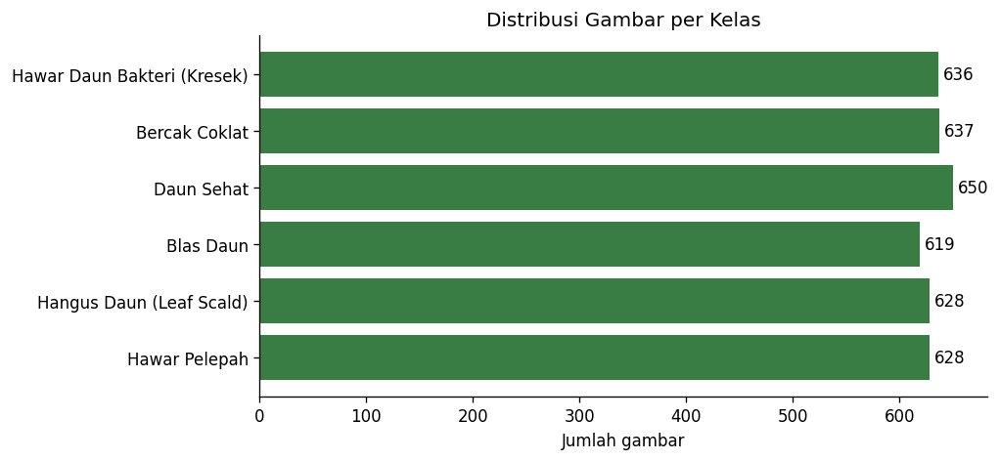

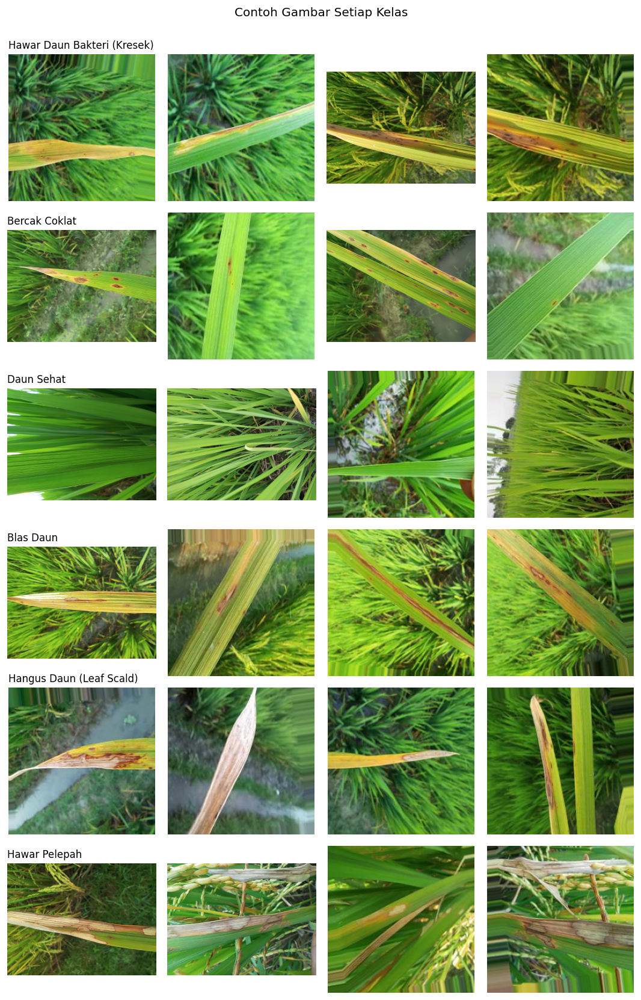

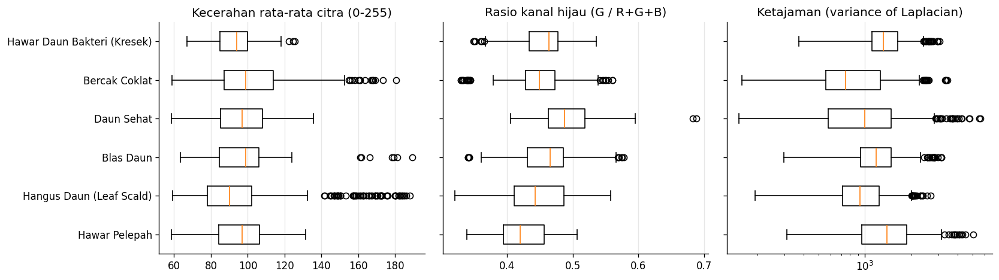

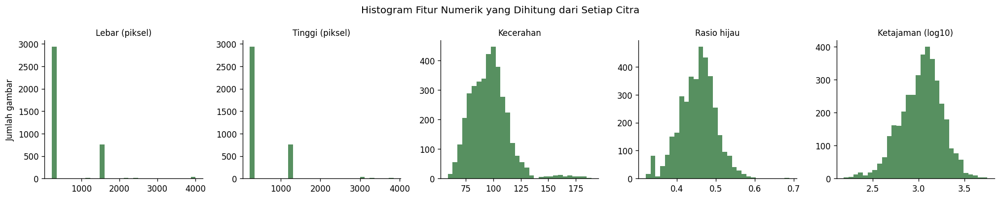

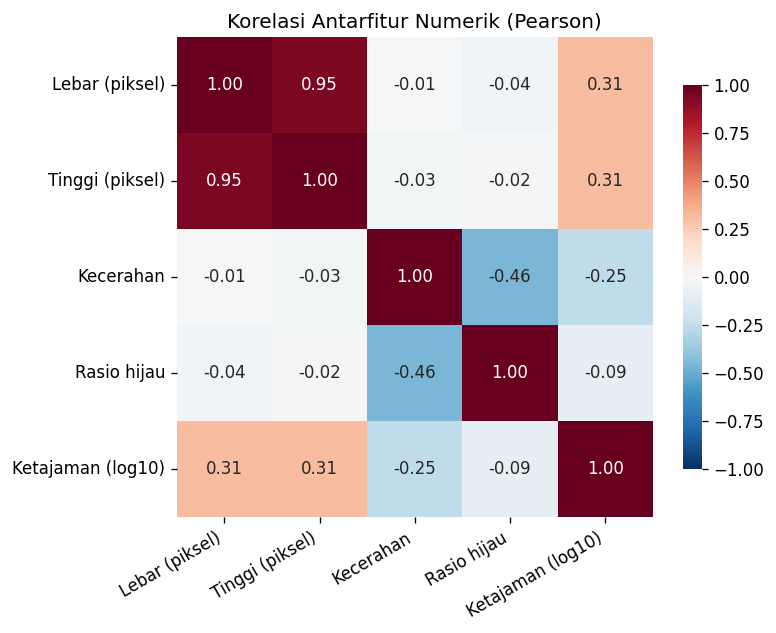

,rata,sd,min,q1,median,q3,maks,iqr,skew,batas_bawah,batas_atas,outlier_bawah,outlier_atas,outlier_z
Lebar (piksel),568.08,688.60,224.00,224.00,224.00,224.00,4000.00,0.00,2.21,224.00,224.00,0.0,867.0,47.0
Tinggi (piksel),484.88,553.90,224.00,224.00,224.00,224.00,3840.00,0.00,2.84,224.00,224.00,0.0,867.0,78.0
Kecerahan,96.54,17.97,58.39,84.11,95.89,105.66,189.45,21.55,1.27,51.79,137.98,0.0,89.0,71.0
Rasio hijau,0.45,0.05,0.32,0.42,0.46,0.48,0.69,0.06,-0.11,0.34,0.57,28.0,19.0,5.0
Ketajaman (log10),3.03,0.23,2.18,2.88,3.05,3.18,3.75,0.30,-0.37,2.44,3.62,49.0,10.0,24.0


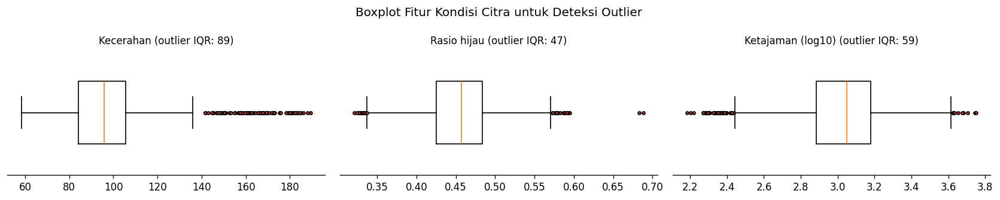

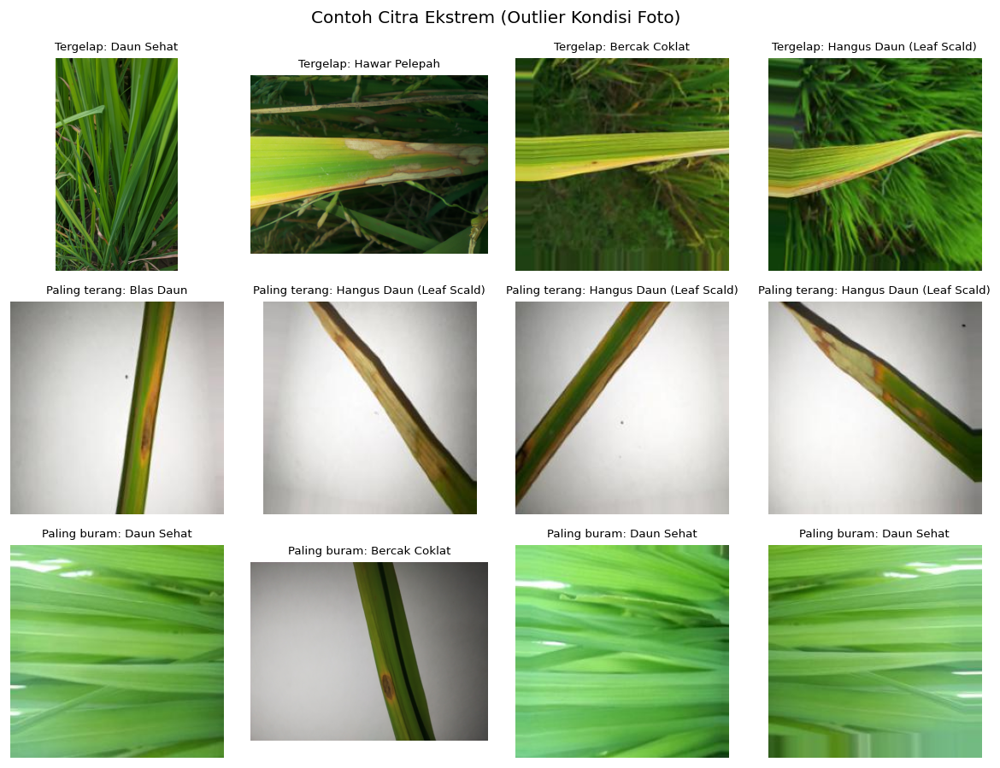

Uji jalan pintas (akurasi 5-fold): {'tebak_mayoritas': 0.171, 'ukuran_saja': 0.234, 'warna_ketajaman': 0.533, 'semua_fitur': 0.58}


,kecerahan_rata,kecerahan_std,hijau_rata,ketajaman_median
Bacterial Leaf Blight,92.884,10.579,0.455,1312.509
Brown Spot,101.408,19.275,0.450,751.536
Healthy Rice Leaf,97.435,15.950,0.492,997.252
Leaf Blast,96.500,15.091,0.458,1177.818
Leaf scald,95.637,26.680,0.443,930.462
Sheath Blight,95.306,14.922,0.424,1395.672


In [ ]:
nama_id = [nama_indonesia(c) for c in CLASS_NAMES]
lebar  = np.array([g["lebar"] for g in info_gambar]); tinggi = np.array([g["tinggi"] for g in info_gambar])
ukuran_unik = Counter(zip(lebar.tolist(), tinggi.tolist()))
print(f"Lebar {lebar.min()}-{lebar.max()} (rata-rata {lebar.mean():.0f}), tinggi {tinggi.min()}-{tinggi.max()} "
      f"(rata-rata {tinggi.mean():.0f}); {len(ukuran_unik)} kombinasi ukuran; tersering {ukuran_unik.most_common(1)}")

# Distribusi kelas
fig, ax = plt.subplots(figsize=(8, 4))
bar = ax.barh(nama_id, list(jumlah_per_kelas.values()), color="#3a7d44")
ax.bar_label(bar, padding=3); ax.set_xlabel("Jumlah gambar"); ax.set_title("Distribusi Gambar per Kelas")
ax.invert_yaxis(); ax.spines[["top", "right"]].set_visible(False)
plt.savefig(f"{HASIL_DIR}/distribusi_kelas.png"); plt.show()

# Contoh 4 gambar per kelas
rng_contoh = np.random.RandomState(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(9, 2.3 * NUM_CLASSES))
for i, c in enumerate(CLASS_NAMES):
    pilih = rng_contoh.choice(np.where(labels == i)[0], min(4, (labels == i).sum()), replace=False)
    for j in range(4):
        ax = axes[i, j]; ax.axis("off")
        if j < len(pilih):
            ax.imshow(Image.open(paths[pilih[j]]).convert("RGB"))
    axes[i, 0].set_title(nama_id[i], fontsize=10, loc="left")
plt.suptitle("Contoh Gambar Setiap Kelas", y=1.0); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/contoh_gambar.png"); plt.show()

# Statistik warna per kelas (variasi kondisi citra)
kecerahan = np.array([g["kecerahan"] for g in info_gambar]); hijau = np.array([g["rasio_hijau"] for g in info_gambar])
tajam = np.array([g["ketajaman"] for g in info_gambar])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
def kotak(ax, data, label, **kw):   # boxplot horizontal, kompatibel matplotlib lama & baru
    try: ax.boxplot(data, orientation="horizontal", tick_labels=label, **kw)
    except TypeError: ax.boxplot(data, vert=False, labels=label, **kw)
kotak(axes[0], [kecerahan[labels == i] for i in range(NUM_CLASSES)], nama_id)
axes[0].set_title("Kecerahan rata-rata citra (0-255)"); axes[0].invert_yaxis()
kotak(axes[1], [hijau[labels == i] for i in range(NUM_CLASSES)], [""] * NUM_CLASSES)
axes[1].set_title("Rasio kanal hijau (G / R+G+B)"); axes[1].invert_yaxis()
kotak(axes[2], [tajam[labels == i] for i in range(NUM_CLASSES)], [""] * NUM_CLASSES)
axes[2].set_title("Ketajaman (variance of Laplacian)"); axes[2].invert_yaxis(); axes[2].set_xscale("log")
for a in axes: a.spines[["top", "right"]].set_visible(False); a.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/statistik_warna.png"); plt.show()

statistik_warna = {c: {"kecerahan_rata": float(kecerahan[labels == i].mean()),
                       "kecerahan_std": float(kecerahan[labels == i].std()),
                       "hijau_rata": float(hijau[labels == i].mean()),
                       "ketajaman_median": float(np.median(tajam[labels == i]))} for i, c in enumerate(CLASS_NAMES)}

# Histogram fitur numerik turunan citra
FITUR_NUM = {"Lebar (piksel)": lebar.astype(float), "Tinggi (piksel)": tinggi.astype(float),
             "Kecerahan": kecerahan, "Rasio hijau": hijau, "Ketajaman (log10)": np.log10(tajam + 1)}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (nm, v) in zip(axes, FITUR_NUM.items()):
    ax.hist(v, bins=30, color="#3a7d44", alpha=.85); ax.set_title(nm, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Jumlah gambar")
plt.suptitle("Histogram Fitur Numerik yang Dihitung dari Setiap Citra"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/histogram_fitur.png"); plt.show()

# Korelasi antarfitur (Pearson)
import pandas as pd
df_fitur = pd.DataFrame(FITUR_NUM)
korelasi = df_fitur.corr().fillna(0)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Korelasi Antarfitur Numerik (Pearson)"); plt.xticks(rotation=30, ha="right")
plt.savefig(f"{HASIL_DIR}/korelasi_fitur.png"); plt.show()
batas_buram = float(np.percentile(tajam, 5))
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Statistik deskriptif lengkap + deteksi outlier (aturan 1,5 x IQR dan |z| > 3)
deskripsi, outlier_mask = {}, {}
for k, v in FITUR_NUM.items():
    q1, med, q3 = np.percentile(v, [25, 50, 75]); iqr = q3 - q1
    z = (v - v.mean()) / (v.std() + 1e-9)
    bawah, atas = v < q1 - 1.5 * iqr, v > q3 + 1.5 * iqr
    outlier_mask[k] = bawah | atas
    deskripsi[k] = {"rata": float(v.mean()), "sd": float(v.std()), "min": float(v.min()), "q1": float(q1),
                    "median": float(med), "q3": float(q3), "maks": float(v.max()), "iqr": float(iqr),
                    "skew": float(stats.skew(v)), "batas_bawah": float(q1 - 1.5 * iqr), "batas_atas": float(q3 + 1.5 * iqr),
                    "outlier_bawah": int(bawah.sum()), "outlier_atas": int(atas.sum()), "outlier_z": int((np.abs(z) > 3).sum())}
FITUR_KONDISI = ["Kecerahan", "Rasio hijau", "Ketajaman (log10)"]          # ukuran tidak dihitung: diseragamkan oleh resize
ada_outlier = np.any([outlier_mask[k] for k in FITUR_KONDISI], axis=0)
display(pd.DataFrame(deskripsi).T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 2.8))
for ax, k in zip(axes, FITUR_KONDISI):
    kotak(ax, [FITUR_NUM[k]], [""], widths=.5, flierprops=dict(marker="o", markersize=3, markerfacecolor="#c0392b"))
    ax.set_title(f"{k} (outlier IQR: {outlier_mask[k].sum()})", fontsize=10); ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.suptitle("Boxplot Fitur Kondisi Citra untuk Deteksi Outlier"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/boxplot_outlier.png"); plt.show()

# Contoh gambar ekstrem: tergelap, paling terang, paling buram
fig, axes = plt.subplots(3, 4, figsize=(10, 7.6))
for r, (judul, urut) in enumerate([("Tergelap", np.argsort(kecerahan)), ("Paling terang", np.argsort(-kecerahan)),
                                    ("Paling buram", np.argsort(tajam))]):
    for j in range(4):
        ax = axes[r, j]; ax.axis("off"); i = urut[j]
        ax.imshow(Image.open(paths[i]).convert("RGB"))
        ax.set_title(f"{judul}: {nama_id[labels[i]]}", fontsize=8)
plt.suptitle("Contoh Citra Ekstrem (Outlier Kondisi Foto)"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/contoh_ekstrem.png"); plt.show()

# Hubungan fitur dengan kelas: Kruskal-Wallis + ukuran efek epsilon^2, dan mutual information
n_, k_ = len(labels), NUM_CLASSES
kruskal = {}
for k, v in FITUR_NUM.items():
    try:
        H, pv = stats.kruskal(*[v[labels == i] for i in range(NUM_CLASSES)])
    except ValueError:                       # semua nilai identik (mis. ukuran seragam)
        H, pv = 0.0, 1.0
    kruskal[k] = {"H": float(H), "p": float(pv), "epsilon2": float(max(0.0, (H - k_ + 1) / (n_ - k_)))}
mi = mutual_info_classif(df_fitur.values, labels, random_state=SEED)
mutual_info = {k: float(v) for k, v in zip(FITUR_NUM, mi)}

# Uji jalan pintas: seberapa akurat fitur sederhana (tanpa CNN) menebak kelas?
cv_grup = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
def akurasi_cv(X):
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
    return float(cross_val_score(rf, X, labels, groups=groups, cv=cv_grup, scoring="accuracy").mean())
jalan_pintas = {"tebak_mayoritas": float(np.bincount(labels).max() / len(labels)),
                "ukuran_saja": akurasi_cv(df_fitur[["Lebar (piksel)", "Tinggi (piksel)"]].values),
                "warna_ketajaman": akurasi_cv(df_fitur[FITUR_KONDISI].values),
                "semua_fitur": akurasi_cv(df_fitur.values)}
print("Uji jalan pintas (akurasi 5-fold):", {k: round(v, 3) for k, v in jalan_pintas.items()})

kualitas = {"total_ditemukan": len(semua), "duplikat": n_duplikat, "rusak": n_rusak, "kosong": n_kosong,
            "terlalu_kecil": n_kecil, "dipakai": int(len(paths)),
            "mode_warna": dict(Counter(g["mode"] for g in info_gambar)),
            "format": dict(Counter(os.path.splitext(p)[1].lower() for p in paths))}
statistik_fitur = {"deskripsi": deskripsi,
                   "korelasi": {a: {b: float(korelasi.loc[a, b]) for b in korelasi.columns} for a in korelasi.index},
                   "ketajaman_persentil5": batas_buram,
                   "kelas_gambar_buram": {c: int(((tajam <= batas_buram) & (labels == i)).sum()) for i, c in enumerate(CLASS_NAMES)},
                   "outlier_gambar": int(ada_outlier.sum()),
                   "outlier_per_kelas": {c: int((ada_outlier & (labels == i)).sum()) for i, c in enumerate(CLASS_NAMES)},
                   "kruskal": kruskal, "mutual_info": mutual_info, "jalan_pintas": jalan_pintas}
display(pd.DataFrame(statistik_warna).T.round(3))

## Langkah 6. Preprocessing b — Resize, rescale piksel, dan fokus daun
1. **Resize** semua gambar ke `IMG_SIZE × IMG_SIZE` dengan `tf.image.resize` (bilinear). Fungsi yang sama dipakai
   website (`fu.siapkan_gambar`), jadi tidak ada perbedaan preprocessing antara training dan pemakaian.
2. **Fokus daun** (lapisan `FokusDaun` di awal model): area daun bergejala dicari dengan warna HSV + operasi
   morfologi **erosi dan dilasi** (max-pooling), lalu latar di luar area itu **dikaburkan** dengan konvolusi
   rata-rata. Tujuannya agar CNN menganalisis daun, bukan tekstur latar (rumpun padi, tanah, air). Jika tidak ada
   gejala (misalnya daun sehat), gambar dibiarkan utuh.
3. **Rescale** piksel 0–255 menjadi 0–1 (lapisan `Rescaling(1/255)` di dalam model).

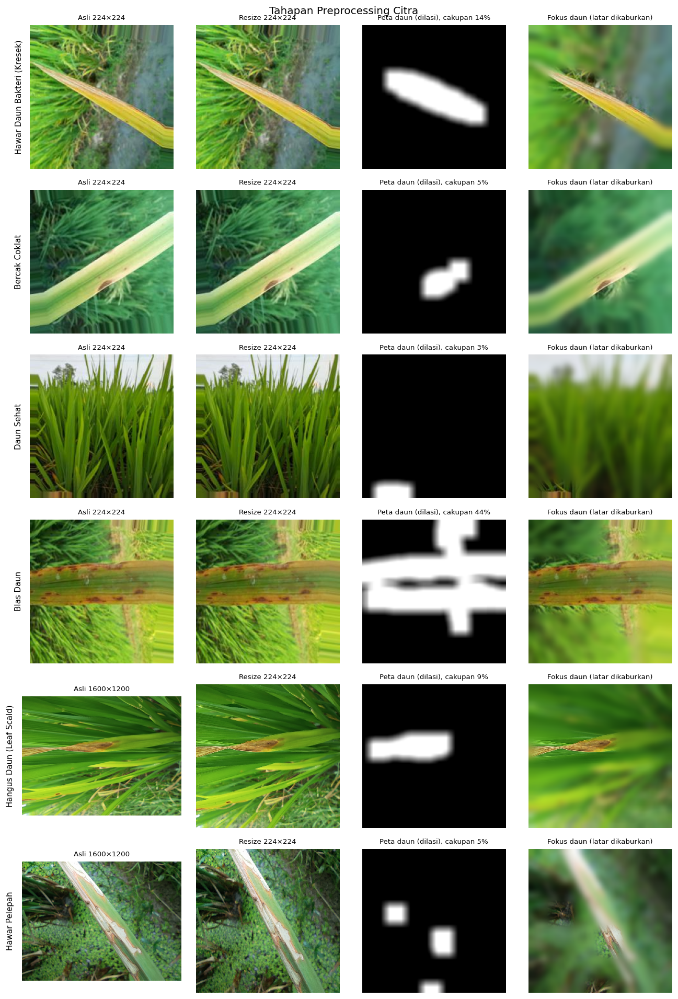

,rata,sd,min,maks
Asli (0-255) | R,96.856,51.753,0.0,255.0
Asli (0-255) | G,130.334,49.017,0.0,255.0
Asli (0-255) | B,64.238,44.827,0.0,255.0
Setelah Rescaling 1/255 | R,0.380,0.203,0.0,1.0
Setelah Rescaling 1/255 | G,0.511,0.192,0.0,1.0
Setelah Rescaling 1/255 | B,0.252,0.176,0.0,1.0


,Jumlah sampel,Porsi fokus aktif,Rata-rata luas area daun
Bacterial Leaf Blight,41.0,1.000,0.188
Brown Spot,29.0,0.724,0.090
Healthy Rice Leaf,39.0,0.359,0.024
Leaf Blast,25.0,1.000,0.249
Leaf scald,30.0,0.933,0.190
Sheath Blight,36.0,0.972,0.242


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
def muat_gambar(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))          # nilai piksel tetap 0-255
    return img, tf.one_hot(label, NUM_CLASSES)

def buat_dataset(x, y, acak=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if acak: ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(muat_gambar, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
rng_pp = np.random.RandomState(SEED)
contoh_pp = [rng_pp.choice(np.where(labels == i)[0]) for i in range(NUM_CLASSES)]
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(11, 2.7 * NUM_CLASSES))
for r, i in enumerate(contoh_pp):
    asli = Image.open(paths[i]).convert("RGB")
    g = fu.siapkan_gambar(asli, IMG_SIZE)
    hasil_fokus, peta, cakupan = fu.terapkan_fokus(g)
    panel = [(asli, f"Asli {asli.size[0]}×{asli.size[1]}"), (np.uint8(g), f"Resize {IMG_SIZE}×{IMG_SIZE}"),
             (peta, f"Peta daun (dilasi), cakupan {cakupan*100:.0f}%"),
             (np.uint8(np.clip(hasil_fokus, 0, 255)), "Fokus daun (latar dikaburkan)" if cakupan >= 0.02 else "Fokus daun: tidak aktif")]
    for c_, (img_, judul) in enumerate(panel):
        if c_ == 2: axes[r, c_].imshow(img_, cmap="gray", vmin=0, vmax=1)
        else: axes[r, c_].imshow(img_)
        axes[r, c_].set_title(judul, fontsize=8); axes[r, c_].axis("off")
    axes[r, 0].text(-0.05, 0.5, nama_indonesia(CLASS_NAMES[labels[i]]), transform=axes[r, 0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=9)
plt.suptitle("Tahapan Preprocessing Citra"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/tahapan_preprocessing.png"); plt.show()

# Statistik piksel sebelum dan sesudah rescaling (sampel 200 gambar)
sampel_idx = np.random.RandomState(SEED).choice(len(paths), min(200, len(paths)), replace=False)
sampel_px = np.stack([fu.siapkan_gambar(Image.open(paths[i]), IMG_SIZE) for i in sampel_idx])
statistik_piksel = {}
for nama, arr in [("Asli (0-255)", sampel_px), ("Setelah Rescaling 1/255", sampel_px / 255.0)]:
    for ci, kanal in enumerate(["R", "G", "B"]):
        v = arr[..., ci]
        statistik_piksel[f"{nama} | {kanal}"] = {"rata": float(v.mean()), "sd": float(v.std()),
                                                 "min": float(v.min()), "maks": float(v.max())}
display(pd.DataFrame(statistik_piksel).T.round(3))

# Seberapa sering fokus daun aktif di setiap kelas (sampel di atas)
cakupan_sampel = np.array([float((fu.peta_daun(g[None])[0, ..., 0].numpy() > 0.5).mean()) for g in sampel_px])
statistik_fokus = {c: {"n": int((labels[sampel_idx] == i).sum()),
                       "aktif": float((cakupan_sampel[labels[sampel_idx] == i] >= 0.02).mean()) if (labels[sampel_idx] == i).any() else 0.0,
                       "cakupan_rata": float(cakupan_sampel[labels[sampel_idx] == i].mean()) if (labels[sampel_idx] == i).any() else 0.0}
                   for i, c in enumerate(CLASS_NAMES)}
display(pd.DataFrame(statistik_fokus).T.rename(columns={"n": "Jumlah sampel", "aktif": "Porsi fokus aktif",
                                                        "cakupan_rata": "Rata-rata luas area daun"}).round(3))

## Langkah 7. Preprocessing c — Augmentasi data (jenis dan parameter)
Augmentasi berupa lapisan Keras yang **hanya aktif saat training**. Ada dua takaran: **ringan** (S2) dan
**minimal** (S3). Baseline (S1) tanpa augmentasi.

,Augmentasi,RandomFlip,RandomRotation,RandomZoom,RandomContrast
0,ringan,horizontal_and_vertical,0.05 (±18°),±10%,±10%
1,minimal,horizontal_and_vertical,0.03 (±11°),±5%,-


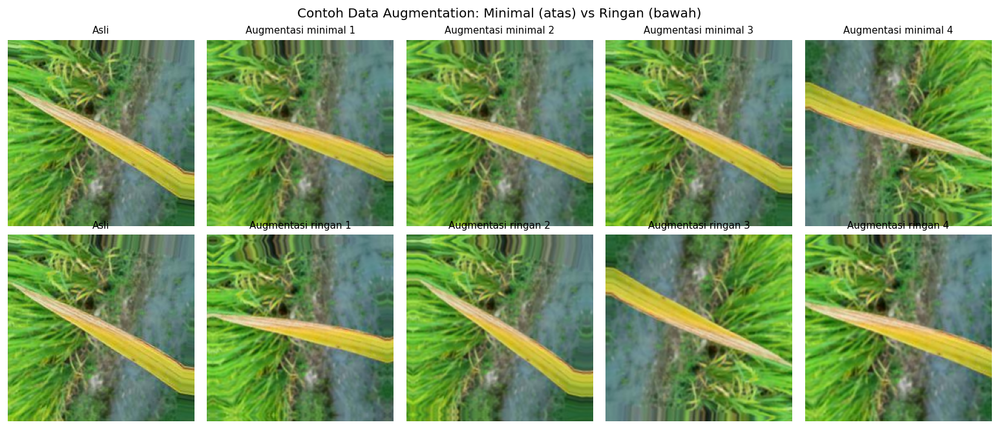

In [ ]:
AUGMENTASI = {
    "ringan": {"flip": "horizontal_and_vertical", "rotasi": 0.05, "zoom": 0.10, "kontras": 0.10},
    "minimal": {"flip": "horizontal_and_vertical", "rotasi": 0.03, "zoom": 0.05, "kontras": 0.0},
}

def lapisan_augmentasi(jenis="ringan"):
    p = AUGMENTASI[jenis]
    lap = [layers.RandomFlip(p["flip"]), layers.RandomRotation(p["rotasi"])]
    if p["zoom"] > 0: lap.append(layers.RandomZoom(p["zoom"]))
    if p["kontras"] > 0: lap.append(layers.RandomContrast(p["kontras"]))   # versi minimal tanpa kontras
    return keras.Sequential(lap, name="data_augmentation")

display(pd.DataFrame([{"Augmentasi": j, "RandomFlip": p["flip"], "RandomRotation": f"{p['rotasi']} (±{p['rotasi']*360:.0f}°)",
                       "RandomZoom": f"±{p['zoom']*100:.0f}%" if p["zoom"] else "-",
                       "RandomContrast": f"±{p['kontras']*100:.0f}%" if p["kontras"] else "-"}
                      for j, p in AUGMENTASI.items()]))

g0 = fu.siapkan_gambar(Image.open(paths[contoh_pp[0]]), IMG_SIZE)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for r, jenis in enumerate(["minimal", "ringan"]):
    aug = lapisan_augmentasi(jenis)
    for j in range(5):
        tampil = g0 if j == 0 else aug(g0[None], training=True)[0].numpy()
        axes[r, j].imshow(np.clip(tampil, 0, 255).astype("uint8")); axes[r, j].axis("off")
        axes[r, j].set_title("Asli" if j == 0 else f"Augmentasi {jenis} {j}", fontsize=9)
plt.suptitle("Contoh Data Augmentation: Minimal (atas) vs Ringan (bawah)"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/contoh_augmentasi.png"); plt.show()

## Langkah 8. Preprocessing d — Missing value, outlier, dan ketidakseimbangan kelas
- **Missing value**: pada citra berupa file rusak/kosong (sudah dibuang di bagian a).
- **Outlier**: gambar dengan kecerahan/rasio hijau/ketajaman ekstrem (aturan 1,5 × IQR dari EDA) **dipertahankan**,
  karena kondisi foto seperti itu juga akan ditemui di lapangan; augmentasi dan fokus daun membantu menanganinya.
- **Ketidakseimbangan kelas**: diukur dengan rasio kelas terbanyak/tersedikit, ditangani dengan **class weight
  balanced** (dihitung dari data latih di bagian e).

In [ ]:
missing_value = {"File rusak": n_rusak, "Gambar kosong/polos": n_kosong, "Gambar terlalu kecil": n_kecil,
                 "Total dibuang (setara missing value)": n_rusak + n_kosong + n_kecil}
display(pd.DataFrame(missing_value.items(), columns=["Jenis", "Jumlah"]))

penanganan_outlier = pd.DataFrame([{"Fitur": k, "Outlier bawah": deskripsi[k]["outlier_bawah"],
                                    "Outlier atas": deskripsi[k]["outlier_atas"],
                                    "Batas bawah": round(deskripsi[k]["batas_bawah"], 2),
                                    "Batas atas": round(deskripsi[k]["batas_atas"], 2),
                                    "Tindakan": "dipertahankan"} for k in FITUR_KONDISI])
display(penanganan_outlier)
print(f"Gambar dengan minimal satu outlier kondisi: {int(ada_outlier.sum())} dari {len(paths)} "
      f"({ada_outlier.mean()*100:.1f}%) -> dipertahankan")

jumlah = np.array(list(jumlah_per_kelas.values()))
rasio_imbalance = float(jumlah.max() / jumlah.min())
print(f"Rasio kelas terbanyak / tersedikit: {rasio_imbalance:.2f} "
      f"({'seimbang' if rasio_imbalance < 1.5 else 'tidak seimbang'}) -> tetap memakai class weight balanced")

,Jenis,Jumlah
0,File rusak,0
1,Gambar kosong/polos,0
2,Gambar terlalu kecil,0
3,Total dibuang (setara missing value),0


,Fitur,Outlier bawah,Outlier atas,Batas bawah,Batas atas,Tindakan
0,Kecerahan,0,89,51.79,137.98,dipertahankan
1,Rasio hijau,28,19,0.34,0.57,dipertahankan
2,Ketajaman (log10),49,10,2.44,3.62,dipertahankan


Gambar dengan minimal satu outlier kondisi: 144 dari 3798 (3.8%) -> dipertahankan
Rasio kelas terbanyak / tersedikit: 1.05 (seimbang) -> tetap memakai class weight balanced


## Langkah 9. Preprocessing e — Pembagian data (training/validation/testing) dan pencegahan kebocoran
**StratifiedGroupKFold** dipakai dua kali: 1/7 data menjadi data uji, lalu 1/6 sisanya menjadi data validasi
(±71% / 14% / 14%). *Stratified* menjaga proporsi kelas; *group* memastikan gambar satu grup (rotasi/flip dari
daun yang sama) tidak tersebar ke data latih dan data uji sekaligus.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
idx_sisa, idx_test = next(sgkf.split(paths, labels, groups))
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
i_tr, i_va = next(sgkf2.split(paths[idx_sisa], labels[idx_sisa], groups[idx_sisa]))
idx_train, idx_val = idx_sisa[i_tr], idx_sisa[i_va]

X_train, y_train = paths[idx_train], labels[idx_train]
X_val, y_val     = paths[idx_val], labels[idx_val]
X_test, y_test   = paths[idx_test], labels[idx_test]

# Pemeriksaan kebocoran data: grup, file identik, dan path yang sama tidak boleh ada di dua bagian
md5_bagian = {nm: {md5_file[p] for p in X} for nm, X in [("train", X_train), ("val", X_val), ("test", X_test)]}
cek_bocor = pd.DataFrame([
    {"Pasangan": f"{a_} – {b_}",
     "Grup sama": len(set(groups[ia]) & set(groups[ib])),
     "File identik (MD5)": len(md5_bagian[a_] & md5_bagian[b_]),
     "Path sama": len(set(paths[ia]) & set(paths[ib]))}
    for (a_, ia), (b_, ib) in [(("train", idx_train), ("test", idx_test)), (("val", idx_val), ("test", idx_test)),
                               (("train", idx_train), ("val", idx_val))]])
display(cek_bocor)
assert cek_bocor[["Grup sama", "File identik (MD5)", "Path sama"]].values.sum() == 0, "Ada kebocoran data!"

split_per_kelas = {c: {"train": int((y_train == i).sum()), "val": int((y_val == i).sum()),
                       "test": int((y_test == i).sum())} for i, c in enumerate(CLASS_NAMES)}
tabel_split = pd.DataFrame(split_per_kelas).T
tabel_split.loc["Total"] = tabel_split.sum()
tabel_split["Proporsi train/val/test"] = [f"{tr/(tr+va+te)*100:.1f}% / {va/(tr+va+te)*100:.1f}% / {te/(tr+va+te)*100:.1f}%"
                                          for tr, va, te in tabel_split[["train", "val", "test"]].values]
display(tabel_split)

# Perbandingan metode pembagian (30 pengulangan seed): proporsi kelas & kebocoran grup ke data uji
from sklearn.model_selection import train_test_split
idx_semua, prop = np.arange(len(labels)), np.bincount(labels) / len(labels)
metode = {"Acak biasa": lambda sd: train_test_split(idx_semua, test_size=1 / 7, random_state=sd),
          "Stratified (tanpa grup)": lambda sd: train_test_split(idx_semua, test_size=1 / 7, random_state=sd, stratify=labels),
          "Stratified + grup (dipakai)": lambda sd: next(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=sd)
                                                         .split(paths, labels, groups))}
banding_split = {}
for nama, fn in metode.items():
    dev, bocor = [], []
    for sd in range(30):
        tr, te = fn(sd)
        p_te = np.bincount(labels[te], minlength=NUM_CLASSES) / len(te)
        dev.append(np.abs(p_te - prop).max() * 100)
        bocor.append(int(np.isin(groups[te], groups[tr]).sum()))
    banding_split[nama] = {"selisih_rata": float(np.mean(dev)), "selisih_maks": float(np.max(dev)),
                           "bocor_rata": float(np.mean(bocor)), "bocor_maks": int(np.max(bocor))}
display(pd.DataFrame(banding_split).T.round(2))

# Dataset tf.data dan class weight (penanganan ketidakseimbangan dari bagian d, dihitung dari data LATIH)
train_ds = buat_dataset(X_train, y_train, acak=True)
val_ds   = buat_dataset(X_val, y_val)
test_ds  = buat_dataset(X_test, y_test)
bobot = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(bobot)}
display(pd.DataFrame({"Kelas": [nama_indonesia(c) for c in CLASS_NAMES], "Jumlah latih": np.bincount(y_train, minlength=NUM_CLASSES),
                      "Class weight": np.round(bobot, 4)}))
print(f"Latih: {len(X_train)} | Validasi: {len(X_val)} | Uji: {len(X_test)}")

,Pasangan,Grup sama,File identik (MD5),Path sama
0,train – test,0,0,0
1,val – test,0,0,0
2,train – val,0,0,0


,train,val,test,Proporsi train/val/test
Bacterial Leaf Blight,455,90,91,71.5% / 14.2% / 14.3%
Brown Spot,455,90,92,71.4% / 14.1% / 14.4%
Healthy Rice Leaf,468,90,92,72.0% / 13.8% / 14.2%
Leaf Blast,438,91,90,70.8% / 14.7% / 14.5%
Leaf scald,454,86,88,72.3% / 13.7% / 14.0%
Sheath Blight,449,91,88,71.5% / 14.5% / 14.0%
Total,2719,538,541,71.6% / 14.2% / 14.2%


,selisih_rata,selisih_maks,bocor_rata,bocor_maks
Acak biasa,2.25,5.14,13.63,20.0
Stratified (tanpa grup),0.09,0.09,14.57,20.0
Stratified + grup (dipakai),0.60,1.55,0.00,0.0


,Kelas,Jumlah latih,Class weight
0,Hawar Daun Bakteri (Kresek),455,0.9960
1,Bercak Coklat,455,0.9960
2,Daun Sehat,468,0.9683
3,Blas Daun,438,1.0346
4,Hangus Daun (Leaf Scald),454,0.9982
5,Hawar Pelepah,449,1.0093


Latih: 2719 | Validasi: 538 | Uji: 541


## Langkah 10. Arsitektur CNN
Satu fungsi membangun tiga skenario dengan arsitektur yang sama: **FokusDaun → (augmentasi) → Rescaling →
4 blok Conv-BN-ReLU-MaxPool → Global Average Pooling → (dropout) → Dense 128 → (dropout) → softmax**.
**S1** tanpa augmentasi & dropout (baseline), **S2** augmentasi ringan + dropout 0,3/0,2, dan **S3** augmentasi
minimal + dropout 0,2/0,1.

In [ ]:
SKENARIO = [
    {"kode": "S1", "nama": "Skenario 1 (tanpa augmentasi & dropout)", "augmentasi": None, "dropout": (0.0, 0.0)},
    {"kode": "S2", "nama": "Skenario 2 (augmentasi ringan + dropout 0,3/0,2)", "augmentasi": "ringan", "dropout": (0.3, 0.2)},
    {"kode": "S3", "nama": "Skenario 3 (augmentasi minimal + dropout 0,2/0,1)", "augmentasi": "minimal", "dropout": (0.2, 0.1)},
]

def buat_model(augmentasi=None, dropout=(0.0, 0.0), nama="PadiCek_CNN"):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_gambar")
    x = fu.FokusDaun(name="fokus_daun")(inputs)        # preprocessing: latar di luar daun dikaburkan
    if augmentasi:                                     # aktif hanya saat training
        x = lapisan_augmentasi(augmentasi)(x)
    x = layers.Rescaling(1.0 / 255, name="rescaling")(x)
    for i, f in enumerate([32, 64, 128, 256], start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"blok{i}_conv")(x)
        x = layers.BatchNormalization(name=f"blok{i}_bn")(x)
        x = layers.Activation("relu", name=f"blok{i}_relu")(x)
        x = layers.MaxPooling2D(2, name=f"blok{i}_pool")(x)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    if dropout[0] > 0: x = layers.Dropout(dropout[0], name="dropout_1")(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    if dropout[1] > 0: x = layers.Dropout(dropout[1], name="dropout_2")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="output_softmax")(x)
    model = keras.Model(inputs, outputs, name=nama)
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

buat_model("ringan", (0.3, 0.2)).summary()

Model: "PadiCek_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_gambar (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fokus_daun (FokusDaun)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_conv (Conv2D)             │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_bn (BatchNormalization)   │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_relu (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok1_pool (MaxPooling2D)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_conv (Conv2D)             │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_bn (BatchNormalization)   │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_relu (Activation)         │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok2_pool (MaxPooling2D)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_conv (Conv2D)             │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_bn (BatchNormalization)   │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_relu (Activation)         │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok3_pool (MaxPooling2D)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_conv (Conv2D)             │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_bn (BatchNormalization)   │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_relu (Activation)         │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ blok4_pool (MaxPooling2D)       │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,526 (1.62 MB)

 Trainable params: 422,566 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## Langkah 11. Training 3 skenario & pemilihan model final
Setiap model yang selesai dilatih **disimpan** ke `model/skenario/`. Jika Colab terputus/di-restart, cukup
**Runtime → Run all** lagi: skenario yang sudah selesai dimuat dari file (tidak dilatih ulang).
Model untuk website dipilih dari **ketiga** skenario berdasarkan **akurasi validasi tertinggi**.

In [ ]:
def latih(m):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ]
    mulai = time.time()
    h = m.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weight, callbacks=callbacks)
    return {k: [float(v) for v in vals] for k, vals in h.history.items()}, time.time() - mulai

def ringkas(m, hist, durasi, sk):
    b = int(np.argmin(hist["val_loss"]))
    tl, ta = m.evaluate(test_ds, verbose=0)
    yp = m.predict(test_ds, verbose=0).argmax(1)
    rep = classification_report(y_test, yp, output_dict=True, zero_division=0)
    return {"kode": sk["kode"], "nama": sk["nama"], "augmentasi": sk["augmentasi"], "dropout": list(sk["dropout"]),
            "parameter": int(m.count_params()), "epoch_dijalankan": len(hist["loss"]), "epoch_terbaik": b + 1,
            "durasi_detik": float(durasi), "train_acc": hist["accuracy"][b], "val_acc": hist["val_accuracy"][b],
            "train_loss": hist["loss"][b], "val_loss": hist["val_loss"][b],
            "test_acc": float(ta), "test_loss": float(tl), "test_f1_macro": float(rep["macro avg"]["f1-score"]),
            "history": hist}

CKPT_DIR = f"{MODEL_DIR}/skenario"; os.makedirs(CKPT_DIR, exist_ok=True)
LATIH_ULANG = os.environ.get("PADICEK_LATIH_ULANG", "0") == "1"      # 1 = abaikan model tersimpan
daftar_skenario = SKENARIO if JALANKAN_SKENARIO_PEMBANDING else [s for s in SKENARIO if s["kode"] == "S3"]
skenario, model_skenario = [], {}
for sk in daftar_skenario:
    print(f"\n===== {sk['nama']} =====")
    tanda = {"img": IMG_SIZE, "epochs": EPOCHS, "n_train": int(len(X_train)), "n_val": int(len(X_val)),
             "seed": SEED, "aug": sk["augmentasi"], "dropout": list(sk["dropout"]), "versi": 2}
    f_model, f_info = f"{CKPT_DIR}/{sk['kode']}.keras", f"{CKPT_DIR}/{sk['kode']}.json"
    if not LATIH_ULANG and os.path.exists(f_model) and os.path.exists(f_info):
        info = json.load(open(f_info))
        if info.get("tanda") == tanda:
            model_skenario[sk["kode"]] = keras.models.load_model(f_model)
            skenario.append(info["ringkas"]); print("Dimuat dari file tersimpan (tidak dilatih ulang).")
            continue
    tf.random.set_seed(SEED)
    m = buat_model(sk["augmentasi"], sk["dropout"], f"PadiCek_{sk['kode']}")
    h, d = latih(m)
    r = ringkas(m, h, d, sk)
    m.save(f_model); json.dump({"tanda": tanda, "ringkas": r}, open(f_info, "w"))
    skenario.append(r); model_skenario[sk["kode"]] = m

terpilih = max(skenario, key=lambda s: (round(s["val_acc"], 3), -s["val_loss"]))
model = model_skenario[terpilih["kode"]]

def alasan_pemilihan(t, semua):
    pc = lambda x: f"{x*100:.2f}%".replace(".", ",")
    dc = lambda x, n=4: f"{x:.{n}f}".replace(".", ",")
    lain = [s for s in semua if s is not t]
    gap = t["train_acc"] - t["val_acc"]
    a = [f"Akurasi validasi tertinggi: {t['kode']} {pc(t['val_acc'])}, dibandingkan "
         + ", ".join(f"{s['kode']} {pc(s['val_acc'])}" for s in lain) + "." if lain else
         f"Hanya {t['kode']} yang dilatih (opsi tanpa skenario pembanding); akurasi validasi {pc(t['val_acc'])}."]
    loss_min = min(s["val_loss"] for s in semua)
    a.append(f"Loss validasi {dc(t['val_loss'])}" + (" (terendah di antara semua skenario)." if t["val_loss"] <= loss_min + 1e-9
             else f" (bukan yang terendah; terendah {dc(loss_min)}), tetapi akurasinya tetap paling tinggi."))
    a.append(f"Selisih akurasi training–validasi {pc(gap)}: " +
             ("tidak ada tanda overfitting berarti." if gap <= 0.05 else
              "overfitting ringan, masih wajar." if gap <= 0.10 else "ada indikasi overfitting, perlu diwaspadai."))
    if t["augmentasi"]:
        a.append(f"Model ini memakai augmentasi {t['augmentasi']} dan dropout {'/'.join(dc(x, 1) for x in t['dropout'])}, "
                 "sehingga lebih tahan terhadap variasi foto (sudut, jarak, kecerahan).")
    else:
        a.append("Model ini tidak memakai augmentasi dan dropout, tetapi tetap dipilih karena terbukti paling akurat pada "
                 "data validasi. Risikonya (kurang tahan terhadap foto yang sangat berbeda dari dataset) diimbangi oleh "
                 "fokus daun, ambang keyakinan, dan fitur potong foto di website.")
    return a

pemilihan = {"aturan": "Akurasi validasi tertinggi di antara semua skenario (data uji tidak dipakai untuk memilih)",
             "terpilih": terpilih["kode"], "alasan": alasan_pemilihan(terpilih, skenario)}
hist, durasi, best_epoch = terpilih["history"], terpilih["durasi_detik"], terpilih["epoch_terbaik"]
for s in skenario:
    s["terpilih"] = s["kode"] == terpilih["kode"]
print(f"MODEL FINAL (dipakai website): {terpilih['nama']}")
print("Alasan pemilihan:")
for a in pemilihan["alasan"]:
    print(" -", a)

lapisan = []
for l in model.layers:
    if isinstance(l, keras.layers.InputLayer): continue
    try: bentuk = str(tuple(l.output.shape))
    except Exception: bentuk = "-"
    akt = getattr(l, "activation", None)
    lapisan.append({"nama": l.name, "tipe": l.__class__.__name__, "output": bentuk,
                    "parameter": int(l.count_params()),
                    "aktivasi": akt.__name__ if callable(akt) and akt.__name__ != "linear" else "-"})


===== Skenario 1 (tanpa augmentasi & dropout) =====
Epoch 1/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.5660 - loss: 1.1795 - val_accuracy: 0.1673 - val_loss: 2.7084 - learning_rate: 0.0010
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 18s 191ms/step - accuracy: 0.6330 - loss: 0.9943 - val_accuracy: 0.1673 - val_loss: 4.2781 - learning_rate: 0.0010
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 187ms/step - accuracy: 0.6914 - loss: 0.8919 - val_accuracy: 0.1729 - val_loss: 4.7387 - learning_rate: 0.0010
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 190ms/step - accuracy: 0.6789 - loss: 0.8533 - val_accuracy: 0.2584 - val_loss: 2.2592 - learning_rate: 0.0010
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 194ms/step - accuracy: 0.7289 - loss: 0.7769 - val_accuracy: 0.2286 - val_loss: 2.7789 - learning_rate: 0.0010
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 20s 182ms/step - accuracy: 0.7223 - loss: 0.7658 - val_accuracy: 0.4405 - val_loss: 1.5374 - learning_rate: 0.0010
Epoch 7/50
85/85 ━━━━━━━━━━━━━━

## Langkah 12. Hasil evaluasi a — Metrik evaluasi yang digunakan dan alasannya

In [ ]:
assert "model" in globals() and "test_ds" in globals(), (
    "Variabel hilang (runtime Colab ter-restart). Jalankan Runtime -> Run all; model yang sudah dilatih akan dimuat "
    "dari model/skenario/ tanpa training ulang.")
tabel_metrik = pd.DataFrame([
    ["Accuracy", "benar / seluruh data", "Gambaran umum; adil dipakai karena kelas hampir seimbang"],
    ["Precision", "TP / (TP + FP)", "Ketepatan saat model menyebut suatu penyakit (hindari penanganan yang tidak perlu)"],
    ["Recall", "TP / (TP + FN)", "Seberapa banyak kasus penyakit yang berhasil dikenali (hindari penyakit terlewat)"],
    ["F1-score", "2PR / (P + R)", "Keseimbangan precision dan recall"],
    ["Macro average", "rata-rata semua kelas", "Acuan utama: setiap kelas dianggap sama penting"],
    ["Loss (categorical cross-entropy)", "-Σ y log(p)", "Error model; dipantau untuk early stopping"],
    ["Confusion matrix", "label asli vs prediksi", "Melihat pasangan kelas yang sering tertukar"],
], columns=["Metrik", "Rumus", "Alasan dipakai"])
display(tabel_metrik)

## Langkah 13. Hasil evaluasi b — Nilai metrik pada data testing

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
laporan = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
print(classification_report(y_test, y_pred, target_names=nama_id, digits=4, zero_division=0))
tabel_uji = pd.DataFrame({nama_indonesia(c): {k: laporan[c][k] for k in ("precision", "recall", "f1-score", "support")}
                          for c in CLASS_NAMES}).T
tabel_uji.loc["Macro average"] = [laporan["macro avg"][k] for k in ("precision", "recall", "f1-score", "support")]
tabel_uji.loc["Weighted average"] = [laporan["weighted avg"][k] for k in ("precision", "recall", "f1-score", "support")]
display(tabel_uji.round(4))
display(pd.DataFrame([{"Akurasi uji": round(test_acc, 4), "Error (1 - akurasi)": round(1 - test_acc, 4),
                       "Loss uji": round(test_loss, 4), "Jumlah uji": len(y_test),
                       "Prediksi benar": int((y_pred == y_test).sum())}]))

## Langkah 14. Hasil evaluasi c — Grafik loss dan akurasi (training vs validation)

In [ ]:
ep = range(1, len(hist["loss"]) + 1)
for kunci, judul, nama_file in [("accuracy", "Akurasi", "grafik_akurasi"), ("loss", "Loss", "grafik_loss")]:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(ep, hist[kunci], label="Training", color="#3a7d44", lw=2)
    ax.plot(ep, hist["val_" + kunci], label="Validasi", color="#d98c1f", lw=2)
    ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Epoch terbaik ({best_epoch})")
    ax.set_xlabel("Epoch"); ax.set_ylabel(judul)
    ax.set_title(f"Grafik {judul} Training vs Validasi (Model Final: {terpilih['kode']})")
    ax.legend(); ax.grid(alpha=.3); ax.spines[["top", "right"]].set_visible(False)
    plt.savefig(f"{HASIL_DIR}/grafik_{'akurasi' if kunci == 'accuracy' else 'loss'}.png"); plt.show()
b_ = best_epoch - 1
display(pd.DataFrame([{"Epoch dijalankan": len(hist["loss"]), "Epoch terbaik": best_epoch,
                       "Akurasi training": round(hist["accuracy"][b_], 4), "Akurasi validasi": round(hist["val_accuracy"][b_], 4),
                       "Loss training": round(hist["loss"][b_], 4), "Loss validasi": round(hist["val_loss"][b_], 4),
                       "LR akhir": hist.get("learning_rate", hist.get("lr", [LEARNING_RATE]))[-1]}]))

## Langkah 15. Fitur unik 1: Grad-CAM (+ pengecekan fokus pada daun)
Baris 1: foto; baris 2: input setelah **fokus daun** (yang benar-benar dilihat CNN); baris 3: Grad-CAM.
Lalu dua pengujian: **deletion test** (menutup 20% area terpenting vs 20% area acak) dan **fokus Grad-CAM pada
daun** (porsi energi Grad-CAM yang jatuh di area daun bergejala dibanding luas area itu; rasio > 1 = model
melihat daun, bukan latar).

In [ ]:
model_cam = fu.buat_model_gradcam(model)
lapisan_fokus = model.get_layer("fokus_daun")
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(2.6 * NUM_CLASSES, 8.2))
for i, c in enumerate(CLASS_NAMES):
    kandidat = np.where((y_test == i) & (y_pred == i))[0]
    kandidat = kandidat if len(kandidat) else np.where(y_test == i)[0]
    g = fu.siapkan_gambar(Image.open(X_test[kandidat[0]]), IMG_SIZE)     # resize identik dengan evaluasi
    cam, prob = fu.gradcam(model_cam, g)
    dilihat = lapisan_fokus(g[None])[0].numpy()
    axes[0, i].imshow(np.clip(g, 0, 255).astype("uint8")); axes[0, i].set_title(nama_id[i], fontsize=9)
    axes[1, i].imshow(np.clip(dilihat, 0, 255).astype("uint8")); axes[1, i].set_title("Setelah fokus daun", fontsize=8)
    axes[2, i].imshow(fu.tempel_heatmap(g, cam))
    axes[2, i].set_title(f"Prediksi: {nama_indonesia(CLASS_NAMES[prob.argmax()])}\n{prob.max()*100:.1f}%", fontsize=8)
for a in axes.flat: a.axis("off")
plt.suptitle("Grad-CAM: area yang paling memengaruhi keputusan model (merah = paling berpengaruh)")
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/gradcam_contoh.png"); plt.show()

n_uji_cam = min(150, len(X_test))
pilih = np.random.RandomState(SEED).choice(len(X_test), n_uji_cam, replace=False)
gambar_cam = [fu.siapkan_gambar(Image.open(X_test[i]), IMG_SIZE) for i in pilih]
fitur_gradcam = fu.uji_penghapusan_gradcam(model_cam, model, gambar_cam, porsi=0.2)
fitur_gradcam["lapisan"] = fu.LAPISAN_KONV_TERAKHIR
fitur_gradcam["ukuran_peta"] = list(cam.shape)
fitur_gradcam["fokus_daun"] = fu.fokus_gradcam_pada_daun(model_cam, gambar_cam)
fd = fitur_gradcam["fokus_daun"]
display(pd.DataFrame([
    ["Deletion test: penurunan keyakinan (area Grad-CAM)", round(fitur_gradcam["penurunan_gradcam"], 4)],
    ["Deletion test: penurunan keyakinan (area acak)", round(fitur_gradcam["penurunan_acak"], 4)],
    ["Deletion test: porsi gambar Grad-CAM > acak", round(fitur_gradcam["persen_lebih_besar"], 4)],
    ["Fokus daun: jumlah gambar dengan area daun bergejala", fd["n"]],
    ["Fokus daun: rata-rata luas area daun", round(fd["luas_daun"], 4)],
    ["Fokus daun: rata-rata energi Grad-CAM di area daun", round(fd["energi_di_daun"], 4)],
    ["Fokus daun: rasio energi / luas (> 1 = fokus ke daun)", round(fd["rasio"], 3)],
    ["Fokus daun: porsi gambar yang fokus ke daun", round(fd["porsi_gambar_fokus"], 4)],
], columns=["Pengujian", "Nilai"]))

## Langkah 16. Fitur unik 2: ambang keyakinan & deteksi input di luar domain
Ambang dipilih dari **data validasi** (ambang terkecil dengan akurasi prediksi diterima ≥ 95%), lalu dampaknya
diukur pada **data uji** dan pada gambar **di luar domain** (noise, warna polos, potongan citra diacak).

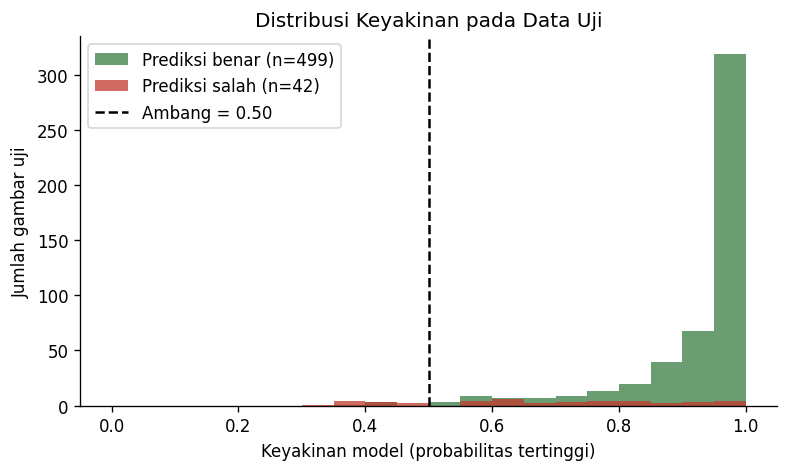

,ambang,cakupan,akurasi,n_diterima
0,0.50,0.9741,0.9393,527
1,0.55,0.9686,0.9389,524
2,0.60,0.9445,0.9452,511
3,0.65,0.9205,0.9558,498
4,0.70,0.9039,0.9591,489
5,0.75,0.8817,0.9644,477
6,0.80,0.8503,0.9717,460
7,0.85,0.8059,0.9794,436
8,0.90,0.7283,0.9822,394
9,0.95,0.5970,0.9876,323


,porsi,akurasi,n
yakin,0.9741,0.9393,527.0
perlu dicek,0.0000,0.0000,0.0
tidak dikenali,0.0259,0.2857,14.0


,n,ditandai,keyakinan_rata,tidak_dikenali
Noise acak,40.0,0.0,0.9832,0.0
Warna polos & gradien,40.0,0.0,0.8929,0.0
Potongan citra diacak,40.0,0.0,0.8808,0.0


In [ ]:
prob_val = model.predict(val_ds, verbose=0)
AMBANG = fu.pilih_ambang(prob_val, y_val, KANDIDAT_AMBANG, TARGET_AKURASI_AMBANG)
tabel_ambang_uji = fu.tabel_ambang(y_prob, y_test, KANDIDAT_AMBANG)
keyakinan = y_prob.max(1); benar = y_pred == y_test
diterima = keyakinan >= AMBANG

contoh_uji = [fu.siapkan_gambar(Image.open(p), IMG_SIZE) for p in X_test[:min(60, len(X_test))]]
ood = fu.buat_input_luar_domain(contoh_uji, IMG_SIZE)
AMBANG_MINIMUM = fu.AMBANG_MINIMUM
hasil_ood = {}
for jenis, arr in ood.items():
    k = model.predict(arr, verbose=0).max(1)
    hasil_ood[jenis] = {"n": int(len(arr)), "ditandai": float((k < AMBANG).mean()), "keyakinan_rata": float(k.mean()),
                        "tidak_dikenali": float((k < AMBANG_MINIMUM).mean())}

tingkat = np.array([fu.status_prediksi(p, AMBANG, AMBANG_MINIMUM)[0] for p in y_prob])
tiga_tingkat = {t: {"porsi": float((tingkat == t).mean()),
                    "akurasi": float(benar[tingkat == t].mean()) if (tingkat == t).any() else 0.0,
                    "n": int((tingkat == t).sum())} for t in ("yakin", "perlu dicek", "tidak dikenali")}

fitur_ambang = {"ambang_minimum": AMBANG_MINIMUM, "tiga_tingkat": tiga_tingkat,
    "ambang": AMBANG, "target_akurasi_val": TARGET_AKURASI_AMBANG, "tabel_uji": tabel_ambang_uji,
    "tanpa_ambang": {"akurasi": float(benar.mean()), "cakupan": 1.0},
    "dengan_ambang": {"akurasi": float(benar[diterima].mean()) if diterima.any() else 0.0,
                      "cakupan": float(diterima.mean()),
                      "salah_tertangkap": float((~diterima[~benar]).mean()) if (~benar).any() else 0.0,
                      "benar_tertolak": float((~diterima[benar]).mean()) if benar.any() else 0.0},
    "keyakinan_rata": {"benar": float(keyakinan[benar].mean()) if benar.any() else 0.0,
                       "salah": float(keyakinan[~benar].mean()) if (~benar).any() else 0.0},
    "ood": hasil_ood,
}

fig, ax = plt.subplots(figsize=(7.5, 4))
bins = np.linspace(0, 1, 21)
ax.hist(keyakinan[benar], bins=bins, alpha=.75, color="#3a7d44", label=f"Prediksi benar (n={benar.sum()})")
ax.hist(keyakinan[~benar], bins=bins, alpha=.75, color="#c0392b", label=f"Prediksi salah (n={(~benar).sum()})")
ax.axvline(AMBANG, color="black", ls="--", label=f"Ambang = {AMBANG:.2f}")
ax.set_xlabel("Keyakinan model (probabilitas tertinggi)"); ax.set_ylabel("Jumlah gambar uji")
ax.set_title("Distribusi Keyakinan pada Data Uji"); ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.savefig(f"{HASIL_DIR}/distribusi_keyakinan.png"); plt.show()
display(pd.DataFrame(tabel_ambang_uji).round(4))
display(pd.DataFrame(tiga_tingkat).T.round(4))
display(pd.DataFrame(hasil_ood).T.round(4))

## Langkah 17. Hasil evaluasi d — Perbandingan antarskenario dan dengan/tanpa fitur unik

,Skenario,Augmentasi,Dropout,Epoch (jalan/terbaik),Akurasi train,Akurasi val,Selisih train-val,Akurasi uji,F1 macro uji,Loss uji,Waktu (menit),Dipakai website
0,S1,-,-,50/49,0.9709,0.9387,0.0323,0.9224,0.9220,0.2482,18.7802,Ya
1,S2,ringan,0.3/0.2,50/43,0.8172,0.8364,-0.0192,0.8299,0.8276,0.5041,15.2440,
2,S3,minimal,0.2/0.1,50/46,0.8613,0.8662,-0.0048,0.8743,0.8735,0.4053,15.0999,


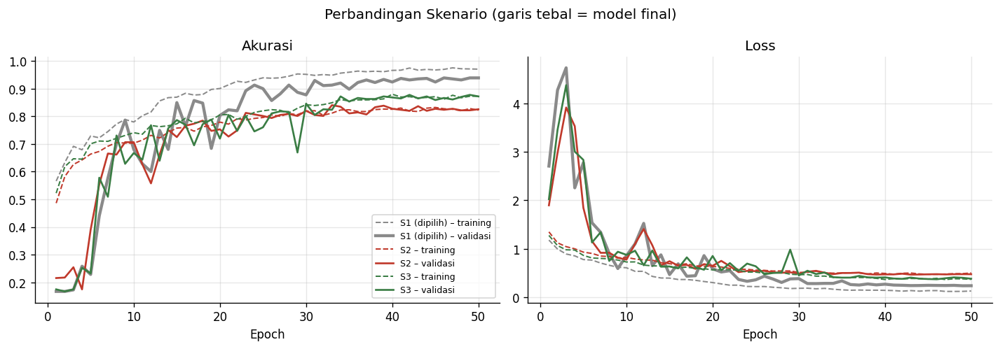

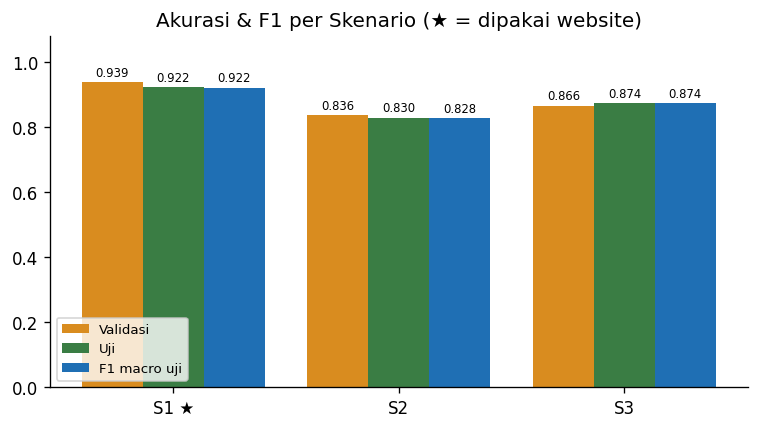

,Fitur,Ukuran,Tanpa fitur / pembanding,Dengan fitur
0,Ambang keyakinan,Akurasi yang ditampilkan ke pengguna,0.9224,0.9393
1,Ambang keyakinan,Porsi foto diberi diagnosis,1.0000,0.9741
2,Ambang keyakinan,Prediksi salah yang tertangkap,0.0000,0.2381
3,Grad-CAM,Penurunan keyakinan saat 20% area ditutup,0.2546,0.6116
4,Grad-CAM + fokus daun,Energi Grad-CAM di area daun (pembanding: luas...,0.2058,0.4184


In [ ]:
tabel_skenario = pd.DataFrame([{"Skenario": s["kode"], "Augmentasi": s["augmentasi"] or "-",
                                "Dropout": "/".join(str(x) for x in s["dropout"]) if any(s["dropout"]) else "-",
                                "Epoch (jalan/terbaik)": f"{s['epoch_dijalankan']}/{s['epoch_terbaik']}",
                                "Akurasi train": s["train_acc"], "Akurasi val": s["val_acc"],
                                "Selisih train-val": s["train_acc"] - s["val_acc"],
                                "Akurasi uji": s["test_acc"], "F1 macro uji": s["test_f1_macro"], "Loss uji": s["test_loss"],
                                "Waktu (menit)": s["durasi_detik"] / 60, "Dipakai website": "Ya" if s["terpilih"] else ""}
                               for s in skenario])
display(tabel_skenario.round(4))

if len(skenario) > 1:
    warna = {"S1": "#8a8a8a", "S2": "#c0392b", "S3": "#3a7d44"}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for s in skenario:
        e = range(1, len(s["history"]["loss"]) + 1); w = warna.get(s["kode"], "#1f77b4")
        tebal = 2.6 if s["terpilih"] else 1.6
        lbl = s["kode"] + (" (dipilih)" if s["terpilih"] else "")
        axes[0].plot(e, s["history"]["accuracy"], color=w, ls="--", lw=1.2, label=f"{lbl} – training")
        axes[0].plot(e, s["history"]["val_accuracy"], color=w, lw=tebal, label=f"{lbl} – validasi")
        axes[1].plot(e, s["history"]["loss"], color=w, ls="--", lw=1.2)
        axes[1].plot(e, s["history"]["val_loss"], color=w, lw=tebal)
    axes[0].set_title("Akurasi"); axes[1].set_title("Loss")
    for a in axes: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.spines[["top", "right"]].set_visible(False)
    axes[0].legend(fontsize=7.5)
    plt.suptitle("Perbandingan Skenario (garis tebal = model final)"); plt.tight_layout()
    plt.savefig(f"{HASIL_DIR}/perbandingan_skenario.png"); plt.show()

    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    xk = np.arange(len(skenario)); lebar_b = 0.27
    for j, (kunci, nm, wr) in enumerate([("val_acc", "Validasi", "#d98c1f"), ("test_acc", "Uji", "#3a7d44"),
                                         ("test_f1_macro", "F1 macro uji", "#1f6fb4")]):
        bar = ax.bar(xk + (j - 1) * lebar_b, [s[kunci] for s in skenario], lebar_b, label=nm, color=wr)
        ax.bar_label(bar, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticks(xk, [s["kode"] + (" ★" if s["terpilih"] else "") for s in skenario]); ax.set_ylim(0, 1.08)
    ax.set_title("Akurasi & F1 per Skenario (★ = dipakai website)"); ax.legend(fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    plt.savefig(f"{HASIL_DIR}/batang_skenario.png"); plt.show()

dengan_tanpa = pd.DataFrame([
    ["Ambang keyakinan", "Akurasi yang ditampilkan ke pengguna", round(fitur_ambang["tanpa_ambang"]["akurasi"], 4),
     round(fitur_ambang["dengan_ambang"]["akurasi"], 4)],
    ["Ambang keyakinan", "Porsi foto diberi diagnosis", 1.0, round(fitur_ambang["dengan_ambang"]["cakupan"], 4)],
    ["Ambang keyakinan", "Prediksi salah yang tertangkap", 0.0, round(fitur_ambang["dengan_ambang"]["salah_tertangkap"], 4)],
    ["Grad-CAM", "Penurunan keyakinan saat 20% area ditutup", round(fitur_gradcam["penurunan_acak"], 4),
     round(fitur_gradcam["penurunan_gradcam"], 4)],
    ["Grad-CAM + fokus daun", "Energi Grad-CAM di area daun (pembanding: luas area daun)",
     round(fitur_gradcam["fokus_daun"]["luas_daun"], 4), round(fitur_gradcam["fokus_daun"]["energi_di_daun"], 4)],
], columns=["Fitur", "Ukuran", "Tanpa fitur / pembanding", "Dengan fitur"])
display(dengan_tanpa)

## Langkah 18. Hasil evaluasi e — Analisis hasil: kelas yang sering salah, penyebab, overfitting/underfitting

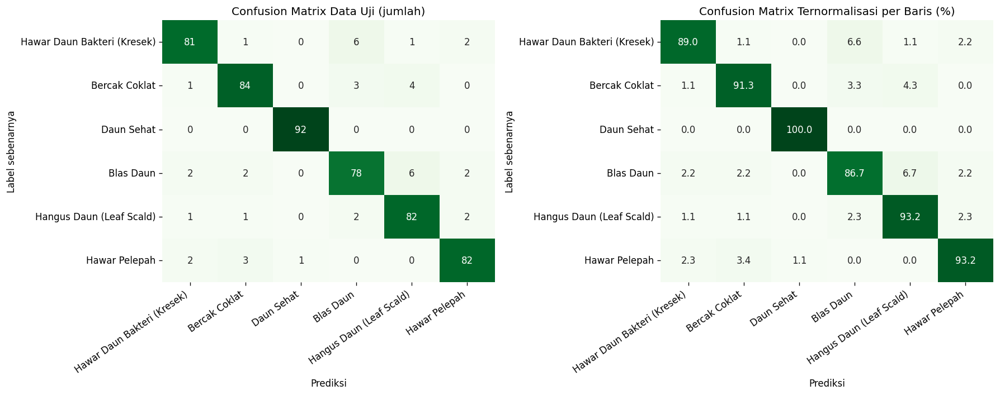

,Asli,Diprediksi,Jumlah,% dari kelas asli,Keyakinan rata-rata,Luas area gejala rata-rata,Kecerahan rata-rata
0,Blas Daun,Hangus Daun (Leaf Scald),6,6.7,0.722,0.109,118.3
1,Hawar Daun Bakteri (Kresek),Blas Daun,6,6.6,0.729,0.270,115.3
2,Bercak Coklat,Hangus Daun (Leaf Scald),4,4.3,0.644,0.168,91.3
3,Hawar Pelepah,Bercak Coklat,3,3.4,0.692,0.209,122.8
4,Bercak Coklat,Blas Daun,3,3.3,0.773,0.188,100.6


,Kelas,Recall,Precision
3,Blas Daun,0.8667,0.8764
0,Hawar Daun Bakteri (Kresek),0.8901,0.9310
1,Bercak Coklat,0.9130,0.9231
4,Hangus Daun (Leaf Scald),0.9318,0.8817
5,Hawar Pelepah,0.9318,0.9318
2,Daun Sehat,1.0000,0.9892


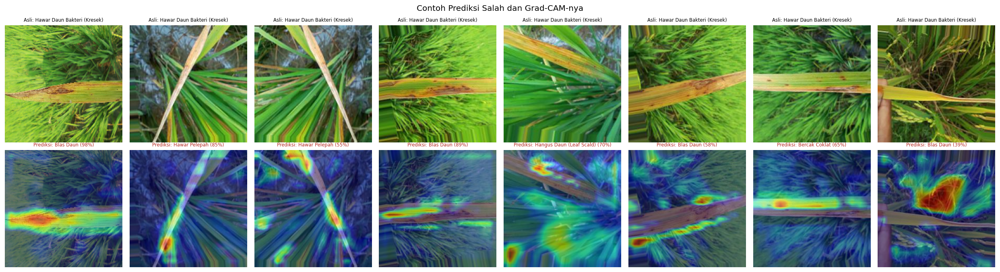

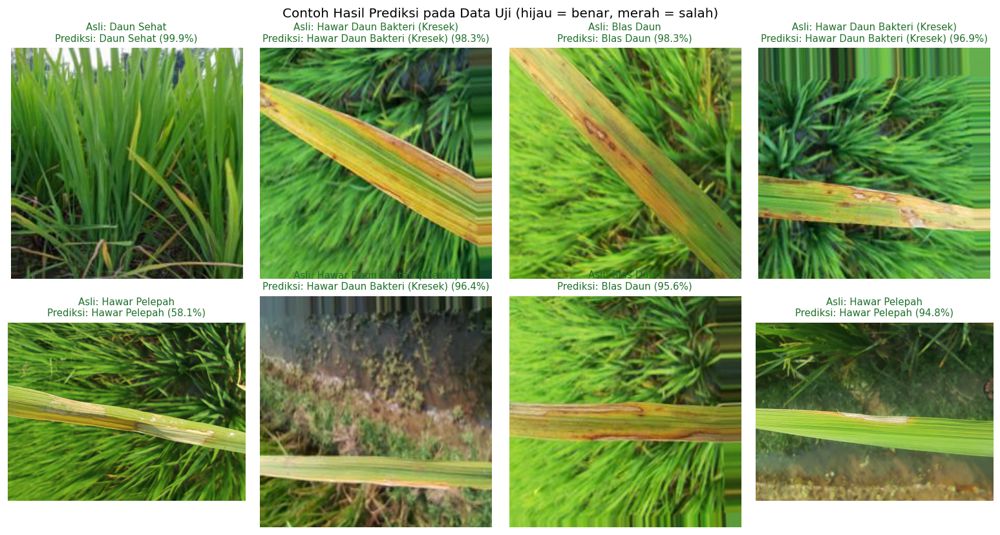

,Skenario,Akurasi train,Akurasi val,Selisih,Loss train,Loss val,Diagnosis
0,S1,0.9709,0.9387,0.0323,0.1199,0.2357,overfitting ringan (selisih 3-10%)
1,S2,0.8172,0.8364,-0.0192,0.4986,0.4658,underfitting (training rendah dan tidak lebih ...
2,S3,0.8613,0.8662,-0.0048,0.3898,0.3695,seimbang (selisih <= 3%)


Akurasi uji model final: 92.24% | Loss uji: 0.2482


In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[0], xticklabels=nama_id, yticklabels=nama_id)
axes[0].set_title("Confusion Matrix Data Uji (jumlah)")
sns.heatmap(cm_norm * 100, annot=True, fmt=".1f", cmap="Greens", cbar=False, ax=axes[1], xticklabels=nama_id, yticklabels=nama_id)
axes[1].set_title("Confusion Matrix Ternormalisasi per Baris (%)")
for a in axes:
    a.set_xlabel("Prediksi"); a.set_ylabel("Label sebenarnya")
    a.set_xticklabels(a.get_xticklabels(), rotation=35, ha="right"); a.set_yticklabels(a.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/confusion_matrix.png"); plt.show()

salah = sorted([(int(cm[i, j]), CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES)
                for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0], reverse=True)
# Data pendukung analisis penyebab untuk 5 pasangan tersering tertukar
fokus_uji = np.array([float((fu.peta_daun(fu.siapkan_gambar(Image.open(p), IMG_SIZE)[None])[0, ..., 0].numpy() > 0.5).mean())
                      for p in X_test])
analisis_tertukar = []
for n, a_, b_ in salah[:5]:
    m_ = (y_test == CLASS_NAMES.index(a_)) & (y_pred == CLASS_NAMES.index(b_))
    analisis_tertukar.append({"Asli": nama_indonesia(a_), "Diprediksi": nama_indonesia(b_), "Jumlah": n,
                              "% dari kelas asli": round(n / max(1, (y_test == CLASS_NAMES.index(a_)).sum()) * 100, 1),
                              "Keyakinan rata-rata": round(float(keyakinan[m_].mean()), 3),
                              "Luas area gejala rata-rata": round(float(fokus_uji[m_].mean()), 3),
                              "Kecerahan rata-rata": round(float(np.mean([np.asarray(Image.open(p).convert('L').resize((64, 64))).mean()
                                                                         for p in X_test[m_]])), 1)})
display(pd.DataFrame(analisis_tertukar))
recall_kelas = pd.DataFrame({"Kelas": nama_id, "Recall": [laporan[c]["recall"] for c in CLASS_NAMES],
                             "Precision": [laporan[c]["precision"] for c in CLASS_NAMES]}).sort_values("Recall")
display(recall_kelas.round(4))

# Contoh prediksi salah + Grad-CAM (untuk melihat penyebabnya)
idx_salah = np.where(y_pred != y_test)[0][:8]
if len(idx_salah):
    fig, axes = plt.subplots(2, len(idx_salah), figsize=(2.6 * len(idx_salah), 5.8), squeeze=False)
    for j, i in enumerate(idx_salah):
        g = fu.siapkan_gambar(Image.open(X_test[i]), IMG_SIZE); cam, _ = fu.gradcam(model_cam, g)
        axes[0, j].imshow(np.uint8(np.clip(g, 0, 255)))
        axes[0, j].set_title(f"Asli: {nama_indonesia(CLASS_NAMES[y_test[i]])}", fontsize=7)
        axes[1, j].imshow(fu.tempel_heatmap(g, cam))
        axes[1, j].set_title(f"Prediksi: {nama_indonesia(CLASS_NAMES[y_pred[i]])} ({keyakinan[i]*100:.0f}%)", fontsize=7, color="#b3261e")
    for a in axes.flat: a.axis("off")
    plt.suptitle("Contoh Prediksi Salah dan Grad-CAM-nya"); plt.tight_layout()
    plt.savefig(f"{HASIL_DIR}/contoh_salah.png"); plt.show()

idx = np.random.RandomState(SEED).choice(len(X_test), min(8, len(X_test)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax in axes.flat: ax.axis("off")
for ax, i in zip(axes.flat, idx):
    ax.imshow(Image.open(X_test[i]).convert("RGB"))
    ax.set_title(f"Asli: {nama_indonesia(CLASS_NAMES[y_test[i]])}\nPrediksi: {nama_indonesia(CLASS_NAMES[y_pred[i]])} "
                 f"({y_prob[i].max()*100:.1f}%)", fontsize=9, color="#1f6f2b" if y_pred[i] == y_test[i] else "#b3261e")
plt.suptitle("Contoh Hasil Prediksi pada Data Uji (hijau = benar, merah = salah)"); plt.tight_layout()
plt.savefig(f"{HASIL_DIR}/contoh_prediksi.png"); plt.show()

def diagnosis(ta, va):
    gap = ta - va
    if ta < 0.70: return "underfitting (akurasi training < 70%)"
    if ta < 0.85 and gap <= 0.03: return "underfitting (training rendah dan tidak lebih tinggi dari validasi)"
    if gap > 0.10: return "overfitting (selisih > 10%)"
    if gap > 0.03: return "overfitting ringan (selisih 3-10%)"
    return "seimbang (selisih <= 3%)"
tabel_diagnosis = pd.DataFrame([{"Skenario": s["kode"], "Akurasi train": round(s["train_acc"], 4),
                                 "Akurasi val": round(s["val_acc"], 4), "Selisih": round(s["train_acc"] - s["val_acc"], 4),
                                 "Loss train": round(s["train_loss"], 4), "Loss val": round(s["val_loss"], 4),
                                 "Diagnosis": diagnosis(s["train_acc"], s["val_acc"])} for s in skenario])
display(tabel_diagnosis)
print(f"Akurasi uji model final: {test_acc*100:.2f}% | Loss uji: {test_loss:.4f}")

## Langkah 19. Simpan model dan hasil (dipakai website)

In [ ]:
model.save(f"{MODEL_DIR}/padicek_model.keras")
with open(f"{MODEL_DIR}/labels.json", "w") as f:
    json.dump({"class_names": CLASS_NAMES, "img_size": IMG_SIZE, "ambang_keyakinan": AMBANG,
               "ambang_minimum": AMBANG_MINIMUM, "skenario": terpilih["kode"]}, f, indent=2)

try:
    gpu = tf.config.experimental.get_device_details(tf.config.list_physical_devices("GPU")[0]).get("device_name", "GPU")
except Exception:
    gpu = "CPU"
versi = {"python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
         "numpy": np.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
         "seaborn": sns.__version__, "pillow": PIL.__version__}
try:
    import streamlit; versi["streamlit"] = streamlit.__version__
except ImportError:
    pass
try:
    import google.colab; lingkungan_nama = "Google Colab"
except ImportError:
    lingkungan_nama = "Komputer lokal (VS Code)"

metrics = {
    "dibuat": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "lingkungan": {"nama": lingkungan_nama, "perangkat": gpu, "os": platform.platform(terse=True), "versi": versi,
                   "python": versi["python"], "tensorflow": versi["tensorflow"]},
    "konfigurasi": {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "epochs_maks": EPOCHS,
                    "learning_rate": LEARNING_RATE, "optimizer": "Adam", "seed": SEED,
                    "augmentasi_parameter": AUGMENTASI, "augmentasi_terpilih": terpilih["augmentasi"],
                    "dropout": list(terpilih["dropout"]), "skenario_terpilih": terpilih["kode"],
                    "early_stopping_patience": 8,
                    "reduce_lr": {"factor": 0.5, "patience": 3, "min_lr": 1e-6}},
    "dataset": {"nama": "Rice Disease Dataset", "kaggle_id": KAGGLE_ID, "url": KAGGLE_URL,
                "folder_sumber": sorted({os.path.relpath(os.path.dirname(os.path.dirname(p)), DATA_DIR) for p, _ in data}),
                "total_ditemukan": len(semua), "duplikat_dihapus": n_duplikat, "rusak_dihapus": n_rusak,
                "total": int(len(paths)), "kelas": CLASS_NAMES, "jumlah_per_kelas": jumlah_per_kelas,
                "format": sorted({os.path.splitext(p)[1].lower() for p in paths}),
                "grup_mirip": {"jumlah_grup": int(n_grup_mirip), "jumlah_gambar": int(n_gambar_dalam_grup),
                               "total_grup": int(len(ukuran_grup)), "grup_terbesar": int(max(ukuran_grup.values())),
                               "batas_hamming": BATAS_HAMMING},
                "split": {"train": int(len(X_train)), "val": int(len(X_val)), "test": int(len(X_test))},
                "split_per_kelas": split_per_kelas,
                "ukuran_asli": {"lebar_min": int(lebar.min()), "lebar_maks": int(lebar.max()), "lebar_rata": float(lebar.mean()),
                                "tinggi_min": int(tinggi.min()), "tinggi_maks": int(tinggi.max()), "tinggi_rata": float(tinggi.mean()),
                                "jumlah_ukuran_unik": len(ukuran_unik),
                                "ukuran_tersering": list(ukuran_unik.most_common(1)[0][0]),
                                "porsi_ukuran_tersering": ukuran_unik.most_common(1)[0][1] / len(paths)},
                "statistik_warna": statistik_warna, "statistik_fitur": statistik_fitur,
                "kualitas": kualitas, "banding_split": banding_split, "statistik_piksel": statistik_piksel},
    "model": {"nama": model.name, "total_parameter": int(model.count_params()),
              "parameter_latih": int(sum(np.prod(v.shape) for v in model.trainable_weights)), "lapisan": lapisan},
    "training": {"epoch_dijalankan": len(hist["loss"]), "epoch_terbaik": best_epoch, "durasi_detik": float(durasi),
                 "history": hist, "class_weight": class_weight},
    "skenario": [{k: v for k, v in s.items() if k != "history"} | {"history": s["history"]} for s in skenario],
    "pemilihan": pemilihan,
    "uji": {"akurasi": float(test_acc), "loss": float(test_loss),
            "macro": {k: float(laporan["macro avg"][k]) for k in ("precision", "recall", "f1-score")},
            "weighted": {k: float(laporan["weighted avg"][k]) for k in ("precision", "recall", "f1-score")},
            "per_kelas": {c: {k: float(laporan[c][k]) for k in ("precision", "recall", "f1-score", "support")}
                          for c in CLASS_NAMES},
            "confusion_matrix": cm.tolist(),
            "tertukar": [{"jumlah": n, "asli": a, "prediksi": b} for n, a, b in salah[:5]]},
    "fitur_ambang": fitur_ambang,
    "fitur_gradcam": fitur_gradcam,
    "preprocessing": {"label_konflik": int(n_konflik), "grup_lintas_kelas": int(len(grup_lintas)),
                      "gambar_grup_lintas_kelas": n_gambar_lintas, "missing_value": missing_value,
                      "rasio_imbalance": rasio_imbalance, "statistik_fokus": statistik_fokus,
                      "cek_bocor": cek_bocor.to_dict(orient="records"),
                      "fokus_daun": {"metode": "HSV gejala + opening 3x3 + dilasi 13x13 + haluskan 7x7; latar dikaburkan",
                                     "min_cakupan": 0.02}},
    "analisis": {"tertukar_detail": analisis_tertukar, "diagnosis": tabel_diagnosis.to_dict(orient="records")},
}
with open(f"{HASIL_DIR}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
with open("requirements.txt", "w") as f:
    f.write(f"streamlit\ntensorflow=={tf.__version__}\nkeras=={keras.__version__}\npillow\nnumpy\nmatplotlib\n")
print("Tersimpan: model/, hasil/metrics.json, requirements.txt")

Tersimpan: model/, hasil/metrics.json, requirements.txt


## Langkah 20. Unduh hasil (`padicek_lengkap.zip`)
Isinya: model terlatih (`model/`), grafik dan `metrics.json` (`hasil/`), serta file website. Simpan zip ini: dipakai untuk menyalakan website lagi, upload ke GitHub, dan membuat laporan.

In [ ]:
import zipfile
def buat_zip(nama_zip="padicek_lengkap.zip"):
    """Zip seluruh project: kode + model + hasil + laporan (siap untuk GitHub / VS Code)."""
    lewati = {"cloudflared", "streamlit.log", "tunnel.log", nama_zip, "__pycache__"}
    with zipfile.ZipFile(f"../{nama_zip}", "w", zipfile.ZIP_DEFLATED) as z:
        for root, dirs, files_ in os.walk("."):
            dirs[:] = [d for d in dirs if d not in lewati]
            for f in files_:
                if f not in lewati:
                    z.write(os.path.join(root, f), os.path.join("padicek", os.path.relpath(os.path.join(root, f), ".")))
    print("Dibuat:", os.path.abspath(f"../{nama_zip}"))
    try:
        from google.colab import files
        files.download(f"../{nama_zip}")
    except ImportError:
        pass
buat_zip()

Dibuat: /content/padicek_lengkap.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Langkah 21. Jalankan website langsung dari Colab 🌐
Memberi **link publik** (`https://....trycloudflare.com`) yang aktif selama tab Colab ini terbuka.

In [ ]:
import subprocess, re, time, os
if not os.path.exists("cloudflared"):
    subprocess.run(["wget", "-q", "-O", "cloudflared",
                    "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64"], check=True)
    os.chmod("cloudflared", 0o755)
subprocess.run("pip install -q streamlit", shell=True)
subprocess.run("pkill -f 'streamlit run' ; pkill -f cloudflared", shell=True)
web = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                       stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                          stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT)
url = None
for _ in range(60):
    time.sleep(1)
    m = re.search(r"https://(?!api\.)[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read())
    if m: url = m.group(0); break
print("Website PadiCek:", url or "gagal membuat link, lihat tunnel.log")
print("(Tunggu ±10 detik sebelum membuka link agar model selesai dimuat)")

Website PadiCek: https://recommends-mature-spread-better.trycloudflare.com
(Tunggu ±10 detik sebelum membuka link agar model selesai dimuat)
